# 🫒 Détection de maladies de l'olivier par Deep Learning

**Projet :** Deep Learning Avancé & MLOps — 3e année Ingénierie IA & Data Science
**Équipe :** [Nom 1], [Nom 2], [Nom 3], [Nom 4]

## Objectif
À partir d'une photo de feuille d'olivier, prédire son état parmi 3 classes :
- `healthy` : feuille saine
- `aculus` : attaque de l'acarien *Aculus olearius*
- `peacock_spot` : œil de paon (*Spilocaea oleagina*, tavelure)

Le modèle renvoie la classe, un score de confiance et une heatmap Grad-CAM expliquant sa décision.

## Plan du notebook
1. Exploration des fichiers
2. Analyse exploratoire des données (EDA)
3. Nettoyage et détection des doublons
4. Découpage des données (train / validation / test)
5. Modèle baseline : ResNet50
6. Modèle avancé : EfficientNet-B0
7. Évaluation et comparaison des modèles
8. Test de généralisation sur une autre source (drift)
9. Explicabilité : Grad-CAM
10. Sauvegarde du modèle final

---
# 1. Exploration des fichiers

## 1.1 Arborescence des données
Nous utilisons deux jeux de données publics hébergés sur Kaggle :

| Source | Auteur | Rôle dans le projet |
| :--- | :--- | :--- |
| *Olive Leaf Image Dataset* (Uğuz & Uysal, 2021) | habibulbasher01644 | Jeu principal (entraînement) |
| *Zeytin* | serhathoca | Jeu externe (test de généralisation / drift) |

Cette cellule affiche l'arborescence des dossiers pour comprendre comment les données sont organisées.

In [6]:
# Cellule 1 : voir quels fichiers on a
import os

for root, dirs, files in os.walk("/kaggle/input"):
    niveau = root.replace("/kaggle/input", "").count(os.sep)
    if niveau <= 3:  # on n'affiche pas trop profond
        print("  " * niveau + os.path.basename(root) + f"/  ({len(files)} fichiers)")

input/  (0 fichiers)
  datasets/  (0 fichiers)
    serhathoca/  (0 fichiers)
      zeytin/  (0 fichiers)
    habibulbasher01644/  (0 fichiers)
      olive-leaf-image-dataset/  (0 fichiers)


## 1.2 Localisation et comptage des images
Les images sont rangées dans des sous-dossiers dont le nom correspond à la classe.
Cette cellule parcourt tous les dossiers et compte les images de chacun.

In [3]:
# Cellule 2 : trouver tous les dossiers qui contiennent des images
import os

RACINE = "/kaggle/input"
EXTENSIONS = (".jpg", ".jpeg", ".png", ".bmp")

for root, dirs, files in os.walk(RACINE):
    images = [f for f in files if f.lower().endswith(EXTENSIONS)]
    if len(images) > 0:
        chemin_court = root.replace(RACINE + "/datasets/", "")
        print(f"{len(images):5d} images  →  {chemin_court}")

  382 images  →  serhathoca/zeytin/hastalıklı
  572 images  →  serhathoca/zeytin/sağlam
  220 images  →  habibulbasher01644/olive-leaf-image-dataset/dataset/test/Healthy
  200 images  →  habibulbasher01644/olive-leaf-image-dataset/dataset/test/aculus_olearius
  260 images  →  habibulbasher01644/olive-leaf-image-dataset/dataset/test/olive_peacock_spot
  830 images  →  habibulbasher01644/olive-leaf-image-dataset/dataset/train/Healthy
  690 images  →  habibulbasher01644/olive-leaf-image-dataset/dataset/train/aculus_olearius
 1200 images  →  habibulbasher01644/olive-leaf-image-dataset/dataset/train/olive_peacock_spot


**Observations :**
- Le jeu **Uğuz** contient 3 400 images, déjà séparées en `train` et `test`, avec 3 classes :
  Healthy (1 050), aculus_olearius (890), olive_peacock_spot (1 460).
- Le jeu **Zeytin** contient 954 images, avec des noms de dossiers en turc :
  `sağlam` = sain (572) et `hastalıklı` = malade (382, identifiées comme *Aculus* par OLIVE-CAD).
- Zeytin **ne contient pas** la classe œil de paon : le test de drift portera donc sur 2 classes.
- Les noms de classes diffèrent entre les deux jeux : il faudra les **harmoniser**.

---
# 2. Analyse exploratoire des données (EDA)

## 2.1 Construction d'un tableau unique
Nous regroupons toutes les images dans un seul DataFrame pandas. Pour chaque image, on enregistre :
- son **chemin**,
- sa **source** (`uguz` ou `zeytin`),
- son **split d'origine** (`train`, `test`, ou `-` si non découpé),
- sa **classe harmonisée** (`healthy`, `aculus`, `peacock_spot`),
- sa **taille** (largeur × hauteur) et son **poids** en Ko.

Ce tableau est sauvegardé dans `images.csv` et sert de base à toutes les étapes suivantes.

**Correspondance des classes :**

| Dossier d'origine | Classe harmonisée |
| :--- | :--- |
| Healthy, sağlam | `healthy` |
| aculus_olearius, hastalıklı | `aculus` |
| olive_peacock_spot | `peacock_spot` |

Nombre total d'images : 4354

classe  aculus  healthy  peacock_spot   All
source                                     
uguz       890     1050          1460  3400
zeytin     382      572             0   954
All       1272     1622          1460  4354

Tailles les plus fréquentes :
800x600     3400
1920x540     788
1912x536     166
Name: count, dtype: int64


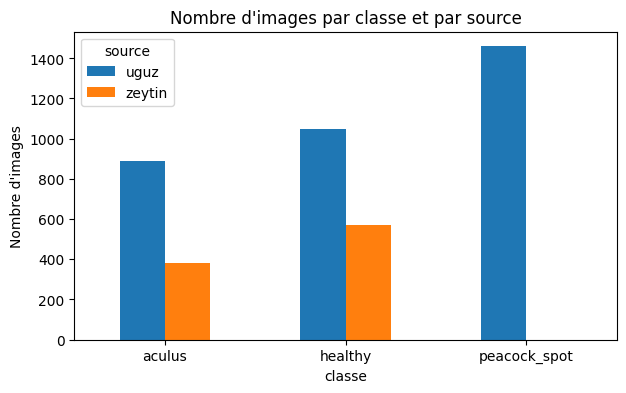

In [4]:
# Cellule 3 : construire un tableau avec toutes les images
import os
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

RACINE = "/kaggle/input/datasets"

# On unifie les noms de classes (les deux jeux n'utilisent pas les mêmes noms)
NOMS_CLASSES = {
    "Healthy": "healthy",
    "aculus_olearius": "aculus",
    "olive_peacock_spot": "peacock_spot",
    "sağlam": "healthy",       # turc : sain
    "hastalıklı": "aculus",    # turc : malade (Aculus d'après OLIVE-CAD)
}

lignes = []
for root, dirs, files in os.walk(RACINE):
    for f in files:
        if not f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp")):
            continue
        chemin = os.path.join(root, f)
        dossier_classe = os.path.basename(root)       # ex : "Healthy"
        source = "uguz" if "habibulbasher" in root else "zeytin"
        split_origine = "test" if "/test/" in root else ("train" if "/train/" in root else "-")
        with Image.open(chemin) as img:
            largeur, hauteur = img.size
        lignes.append({
            "chemin": chemin,
            "source": source,
            "split_origine": split_origine,
            "classe": NOMS_CLASSES[dossier_classe],
            "largeur": largeur,
            "hauteur": hauteur,
            "poids_ko": round(os.path.getsize(chemin) / 1024, 1),
        })

df = pd.DataFrame(lignes)
print("Nombre total d'images :", len(df))
print()

# 1) Combien d'images par source et par classe ?
print(pd.crosstab(df["source"], df["classe"], margins=True))
print()

# 2) Quelles tailles d'images ?
print("Tailles les plus fréquentes :")
print((df["largeur"].astype(str) + "x" + df["hauteur"].astype(str)).value_counts().head(5))

# 3) Graphique : répartition des classes par source
pd.crosstab(df["classe"], df["source"]).plot(kind="bar", figsize=(7, 4))
plt.title("Nombre d'images par classe et par source")
plt.ylabel("Nombre d'images")
plt.xticks(rotation=0)
plt.show()

# On sauvegarde le tableau pour la suite
df.to_csv("/kaggle/working/images.csv", index=False)

**Observations :**
- **4 354 images** au total : 3 400 (Uğuz) + 954 (Zeytin).
- **Déséquilibre modéré** dans Uğuz : `peacock_spot` 43 %, `healthy` 31 %, `aculus` 26 %
  (rapport max/min ≈ 1,6). On utilisera le **F1-score macro** en plus de l'exactitude.
- **Zeytin n'a pas de classe `peacock_spot`** : le test de généralisation portera sur 2 classes.
- **Tailles d'images très différentes selon la source :**
  - Uğuz : toutes en **800×600** (format 4:3, homogène),
  - Zeytin : **1920×540** ou **1912×536** (format très allongé, ≈ 3,5:1).
- Cette différence de format est un **premier signe de décalage de distribution (drift)** entre les sources :
  un modèle entraîné sur Uğuz verra des images très différentes sur Zeytin.

## 2.2 Visualisation d'exemples
Avant toute modélisation, on regarde quelques images de chaque classe et de chaque source pour :
- vérifier que les étiquettes semblent correctes,
- observer les conditions de prise de vue (fond, éclairage, cadrage),
- comprendre le format inhabituel des images Zeytin.

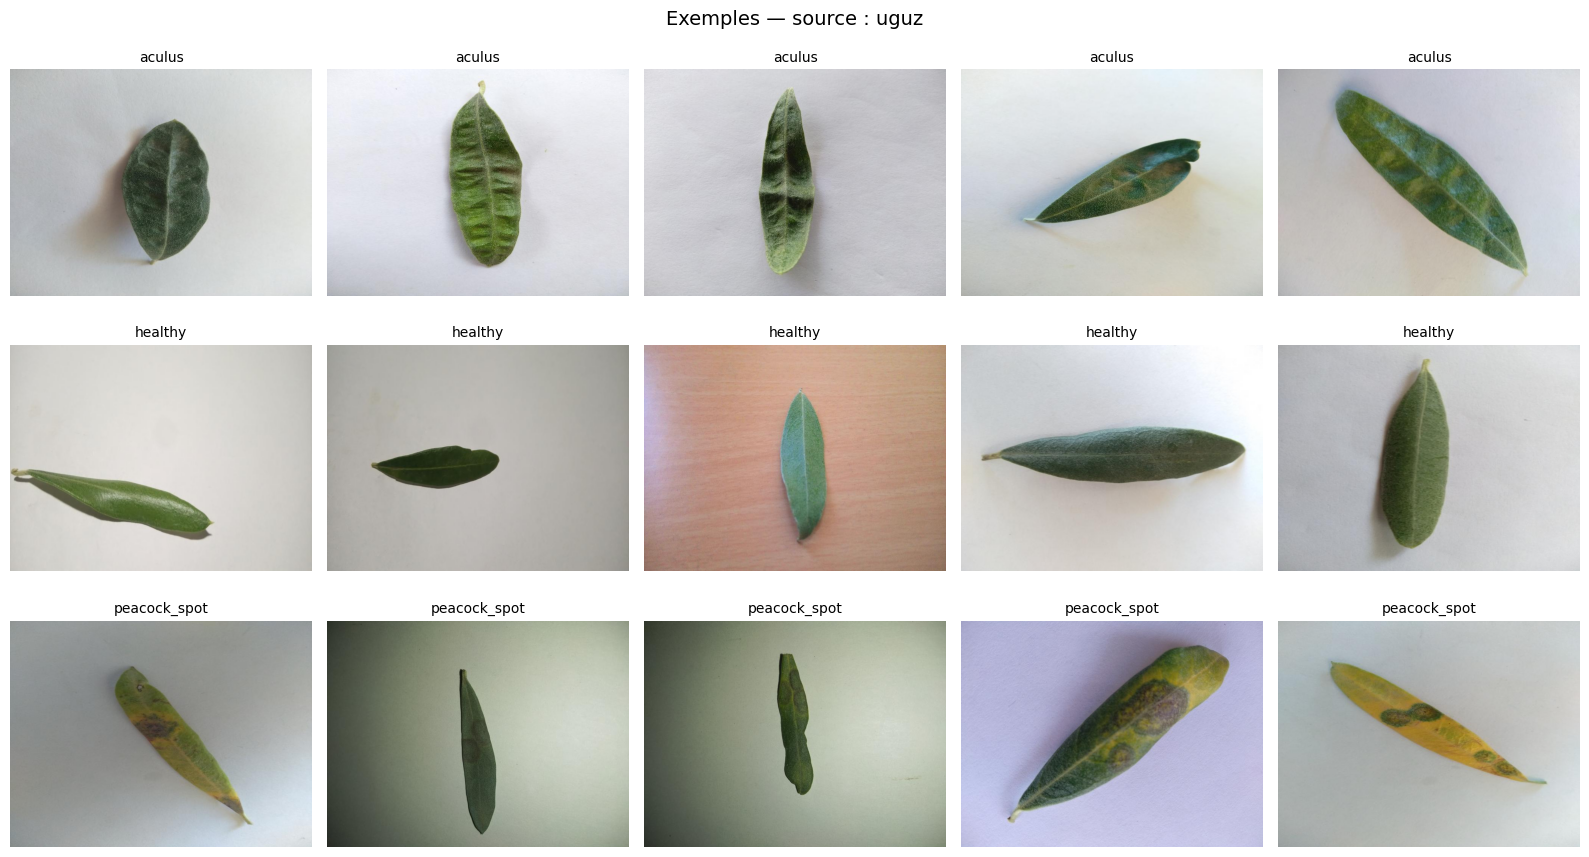

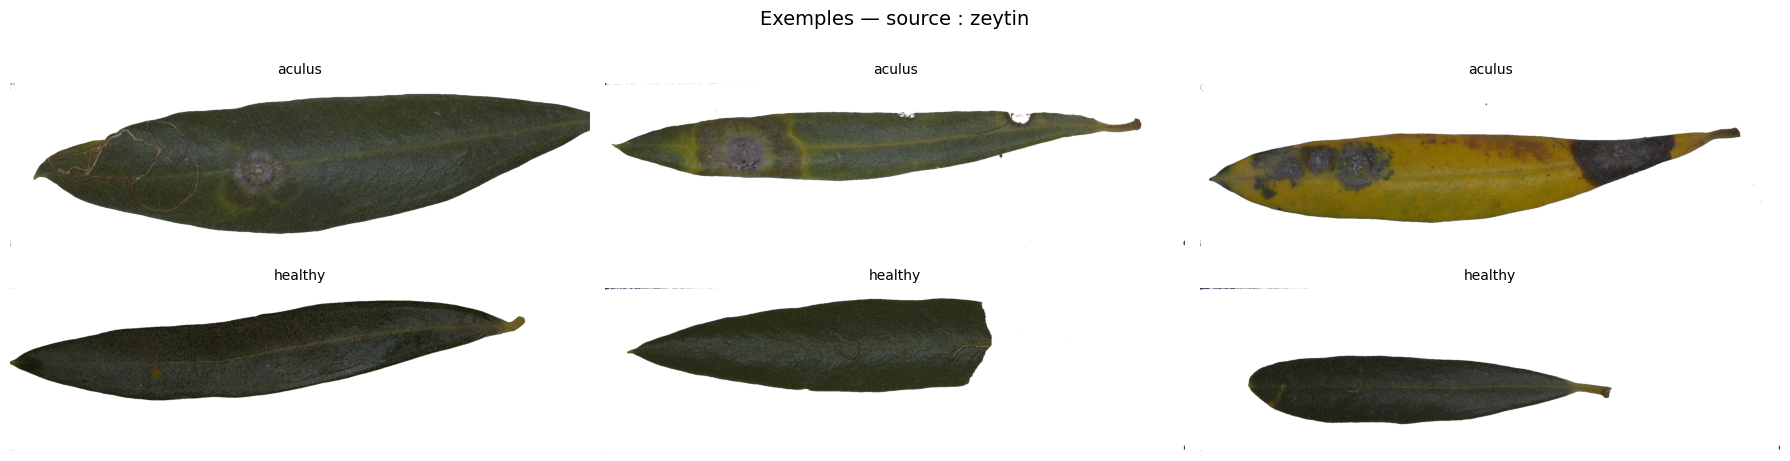

In [7]:
# Cellule 4 : afficher quelques images par source et par classe
import matplotlib.pyplot as plt
from PIL import Image

def afficher_exemples(source, n=4, largeur_fig=16, hauteur_ligne=3):
    sous_df = df[df["source"] == source]
    classes = sorted(sous_df["classe"].unique())
    fig, axes = plt.subplots(len(classes), n, figsize=(largeur_fig, hauteur_ligne * len(classes)))
    for i, classe in enumerate(classes):
        exemples = sous_df[sous_df["classe"] == classe].sample(n, random_state=1)
        for j, chemin in enumerate(exemples["chemin"]):
            ax = axes[i, j]
            ax.imshow(Image.open(chemin))
            ax.set_title(classe, fontsize=10)
            ax.axis("off")
    fig.suptitle(f"Exemples — source : {source}", fontsize=14)
    plt.tight_layout()
    plt.show()

afficher_exemples("uguz", n=5)
afficher_exemples("zeytin", n=3, largeur_fig=18, hauteur_ligne=2.5)

**Observations :**
- **Uğuz** : une feuille isolée par image, sur fond uni, mais la **couleur du fond varie** (blanc, gris, rose, bleu)
  ainsi que l'éclairage. Risque : le modèle pourrait apprendre le fond plutôt que les symptômes
  → à vérifier avec **Grad-CAM**.
- **Zeytin** : feuilles **scannées** sur fond blanc, cadrage serré et horizontal (d'où le format 1920×540).
  Conditions d'acquisition très différentes d'Uğuz → **décalage de distribution (drift)**.
- ⚠️ **Incohérence d'étiquetage** : les images Zeytin du dossier `hastalıklı` (« malade »), considérées comme
  *Aculus* par OLIVE-CAD, présentent visuellement des **taches circulaires brunes avec jaunissement**,
  caractéristiques de l'**œil de paon**. L'étiquette fine de cette source n'est donc pas fiable.

**Décisions :**
1. Le test sur Zeytin sera évalué en **binaire : sain / malade** (toute prédiction `aculus` ou `peacock_spot`
   compte comme « malade »).
2. Les images seront **complétées en carré par des bandes blanches (padding)** avant le redimensionnement
   en 224×224, afin de ne pas déformer les feuilles.

---
# 3. Nettoyage : détection des doublons

## 3.1 Pourquoi chercher les doublons ?
Si une même image (ou une version presque identique) se trouve à la fois dans l'entraînement et dans le test,
le modèle est évalué sur des images qu'il a déjà vues : le score est **artificiellement gonflé**
(fuite de données, *data leakage*).

## 3.2 Méthode : empreinte perceptuelle (dHash)
Chaque image est réduite à une **empreinte de 64 bits** qui résume sa structure visuelle :
1. conversion en niveaux de gris et réduction à 9×8 pixels,
2. pour chaque pixel, on note s'il est plus clair que son voisin de droite (1) ou non (0).

Deux images presque identiques ont des empreintes presque identiques. On compte le nombre de bits différents
(**distance de Hamming**) : une distance ≤ 4 sur 64 indique un doublon probable.

Nombre de paires de doublons probables : 6555

Où se trouvent-elles ?
groupe_1    groupe_2  
uguz/test   uguz/test      216
            uguz/train    1227
uguz/train  uguz/train    5061
zeytin/-    uguz/train      10
            zeytin/-        41
dtype: int64

Doublons avec des classes DIFFÉRENTES (erreurs d'étiquette ?) : 2983


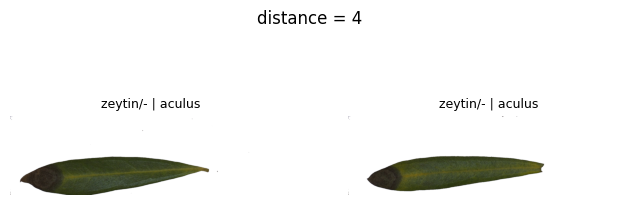

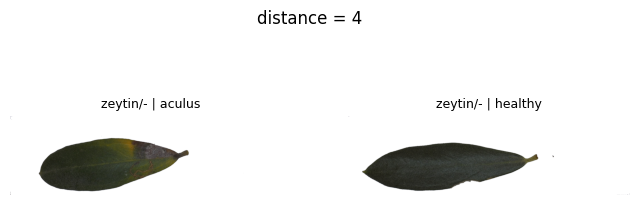

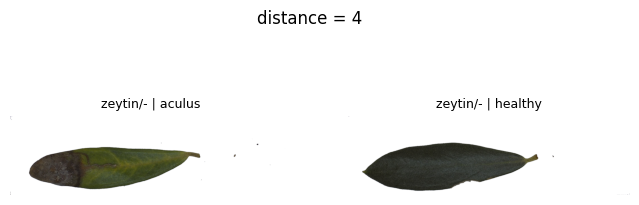

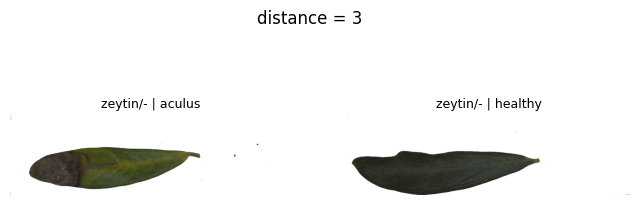

In [8]:
# Cellule 5 : détection des doublons avec une empreinte perceptuelle (dHash)
import numpy as np
from PIL import Image
from concurrent.futures import ThreadPoolExecutor

def empreinte(chemin):
    with Image.open(chemin) as img:
        img.draft("L", (64, 64))                    # décodage JPEG rapide, en petit
        img = img.convert("L").resize((9, 8))       # gris + 9x8 pixels
    px = np.asarray(img, dtype=np.int16)
    return (px[:, 1:] > px[:, :-1]).flatten()       # 64 valeurs vrai/faux

# 1) Calculer l'empreinte de chaque image (16 en parallèle)
with ThreadPoolExecutor(max_workers=16) as ex:
    empreintes = list(ex.map(empreinte, df["chemin"]))
B = np.array(empreintes, dtype=np.float32)          # tableau 4354 x 64

# 2) Distance de Hamming entre TOUTES les paires d'images, en une opération
D = B @ (1 - B).T + (1 - B) @ B.T
np.fill_diagonal(D, 999)                            # on ignore une image comparée à elle-même

# 3) Garder les paires très proches
SEUIL = 4
i_idx, j_idx = np.where(np.triu(D <= SEUIL))

df["groupe"] = df["source"] + "/" + df["split_origine"]
paires = pd.DataFrame({
    "img_1": df["chemin"].values[i_idx],
    "img_2": df["chemin"].values[j_idx],
    "groupe_1": df["groupe"].values[i_idx],
    "groupe_2": df["groupe"].values[j_idx],
    "classe_1": df["classe"].values[i_idx],
    "classe_2": df["classe"].values[j_idx],
    "distance": D[i_idx, j_idx].astype(int),
})
paires["meme_classe"] = paires["classe_1"] == paires["classe_2"]

print("Nombre de paires de doublons probables :", len(paires))
print()
print("Où se trouvent-elles ?")
print(paires.groupby(["groupe_1", "groupe_2"]).size())
print()
print("Doublons avec des classes DIFFÉRENTES (erreurs d'étiquette ?) :", (~paires["meme_classe"]).sum())

# 4) Montrer quelques paires pour vérifier à l'œil
for _, p in paires.head(4).iterrows():
    fig, axes = plt.subplots(1, 2, figsize=(8, 3))
    for ax, chemin, groupe, classe in [(axes[0], p.img_1, p.groupe_1, p.classe_1),
                                       (axes[1], p.img_2, p.groupe_2, p.classe_2)]:
        ax.imshow(Image.open(chemin)); ax.set_title(f"{groupe} | {classe}", fontsize=9); ax.axis("off")
    fig.suptitle(f"distance = {p.distance}")
    plt.show()

paires.to_csv("/kaggle/working/doublons.csv", index=False)

**Observations :**
- Avec une empreinte de 64 bits (image réduite à 9×8 pixels) et un seuil de 4, on obtient **6 555 paires suspectes**,
  dont **2 983 entre classes différentes**.
- L'inspection visuelle montre qu'il s'agit de **feuilles différentes** : ce sont des **faux positifs**.
- **Cause** : la feuille occupe une petite partie de l'image, sur un fond uni. À 9×8 pixels, toutes les images
  se ressemblent (« forme sombre allongée sur fond clair »).

**Conclusion :** cette méthode est trop grossière pour nos données. On la remplace par deux contrôles plus fiables :
une comparaison **exacte** des fichiers (MD5) et une empreinte perceptuelle **plus fine** (16×16 = 256 bits).

## 3.3 Contrôle affiné des doublons
1. **Copies exactes (MD5)** : deux fichiers strictement identiques ont la même empreinte MD5 → aucun faux positif.
2. **Quasi-doublons (dHash 256 bits)** : empreinte calculée sur une image réduite à 16×16, 4 fois plus précise.
   On observe la distribution des distances pour choisir un seuil justifié.

1) COPIES EXACTES
   Images concernées : 178 | groupes de copies : 84
                                                               groupes  \
md5                                                                      
06932651980143bf26c6d5217abed9c4              [uguz/train, uguz/train]   
09b432320e09849f81ffcd9fdc131e91              [uguz/train, uguz/train]   
0b764450c49f37e7012a20a4d4d5dc6b              [uguz/train, uguz/train]   
13bac3c6ecac6f9ffc41b2e3d2be6280               [uguz/test, uguz/train]   
15d1c708e2f69ea393b1d41d01a46826              [uguz/train, uguz/train]   
18891a4d3b664945296bd230796e0737              [uguz/train, uguz/train]   
19191d5ee94ea404598a74dafcabcaa9              [uguz/train, uguz/train]   
1b4755c055a7973722f0b997597e29c0  [uguz/train, uguz/train, uguz/train]   
1e0e817e8ebfff25c6a698c08f556498               [uguz/test, uguz/train]   
20a20e1ba5d8493f76ef456b307ad888              [uguz/train, uguz/train]   

                                         

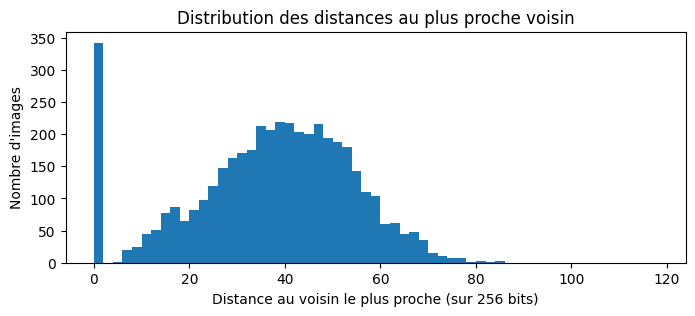

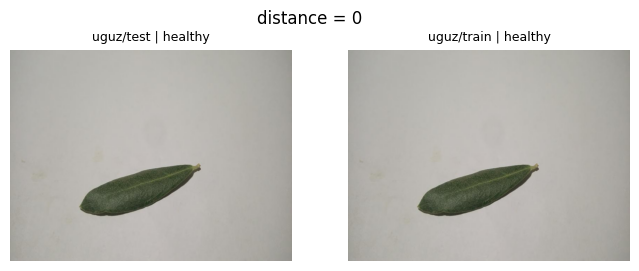

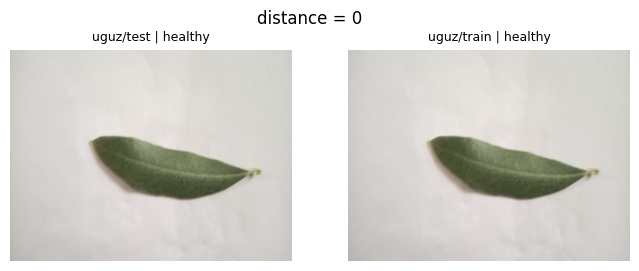

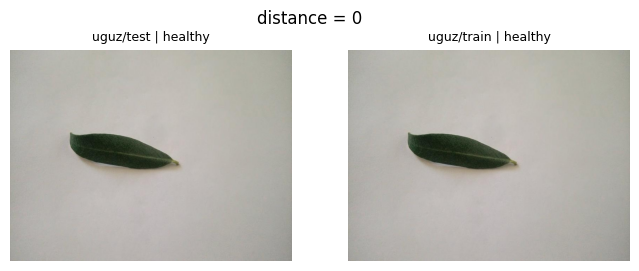

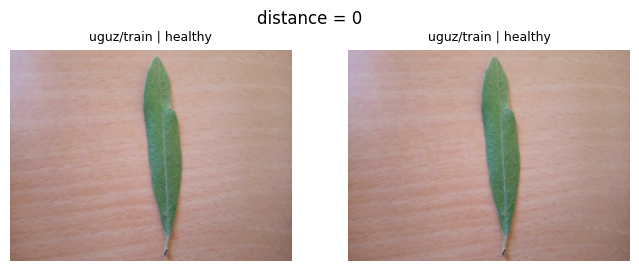

In [9]:
# Cellule 6 : contrôle affiné des doublons
import hashlib

# --- 1) Copies EXACTES (même fichier, octet par octet) ---
def md5(chemin):
    with open(chemin, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

with ThreadPoolExecutor(max_workers=16) as ex:
    df["md5"] = list(ex.map(md5, df["chemin"]))

exacts = df[df.duplicated("md5", keep=False)]
print("1) COPIES EXACTES")
print("   Images concernées :", len(exacts), "| groupes de copies :", exacts["md5"].nunique())
if len(exacts) > 0:
    print(exacts.groupby("md5").agg(groupes=("groupe", list), classes=("classe", list)).head(10))
print()

# --- 2) Quasi-doublons avec une empreinte plus fine (16x16 = 256 bits) ---
def empreinte16(chemin):
    with Image.open(chemin) as img:
        img.draft("L", (128, 128))
        img = img.convert("L").resize((17, 16))
    px = np.asarray(img, dtype=np.int16)
    return (px[:, 1:] > px[:, :-1]).flatten()

with ThreadPoolExecutor(max_workers=16) as ex:
    B16 = np.array(list(ex.map(empreinte16, df["chemin"])), dtype=np.float32)

D16 = B16 @ (1 - B16).T + (1 - B16) @ B16.T
np.fill_diagonal(D16, 999)

# Pour chaque image : distance à son voisin le plus proche
df["dist_voisin"] = D16.min(axis=1)

print("2) QUASI-DOUBLONS (256 bits)")
for s in [0, 5, 10, 20]:
    print(f"   Images ayant un voisin à distance <= {s:2d} : {(df['dist_voisin'] <= s).sum()}")

plt.figure(figsize=(8, 3))
plt.hist(df["dist_voisin"], bins=range(0, 120, 2))
plt.xlabel("Distance au voisin le plus proche (sur 256 bits)")
plt.ylabel("Nombre d'images")
plt.title("Distribution des distances au plus proche voisin")
plt.show()

# --- 3) Afficher les 4 paires les PLUS proches ---
i_idx, j_idx = np.where(np.triu(D16 < 999))
ordre = np.argsort(D16[i_idx, j_idx])[:4]
for k in ordre:
    i, j = i_idx[k], j_idx[k]
    fig, axes = plt.subplots(1, 2, figsize=(8, 3))
    for ax, idx in [(axes[0], i), (axes[1], j)]:
        ax.imshow(Image.open(df["chemin"].iloc[idx]))
        ax.set_title(f"{df['groupe'].iloc[idx]} | {df['classe'].iloc[idx]}", fontsize=9)
        ax.axis("off")
    fig.suptitle(f"distance = {int(D16[i, j])}")
    plt.show()

**Observations :**
- **Copies exactes (MD5)** : **178 images** réparties en **84 groupes**, toutes de même classe ; certaines copies sont
  à la fois dans `uguz/train` et `uguz/test`.
- **Quasi-doublons (256 bits)** : 342 images ont une voisine à distance 0, 343 à ≤ 5, 410 à ≤ 10 et 759 à ≤ 20.
  Le nombre augmente très peu entre 0 et 10, puis fortement au-delà : les vrais doublons sont sous 10.
- **Distribution des distances (256 bits)** : la majorité des images ont leur plus proche voisine à une distance
  de 25 à 80 ; un **petit groupe isolé près de 0** correspond aux doublons. La séparation est nette
  → seuil retenu : **distance ≤ 10**.
- ⚠️ **Fuite de données dans le découpage d'origine** : certaines images apparaissent **à la fois dans
  `train` et dans `test`** du jeu Uğuz. Les scores publiés sur ce découpage sont donc probablement surestimés.

**Décision :** on ignore le découpage d'origine, on garde **une seule image par groupe de doublons**,
et on construit notre propre découpage.

---
# 4. Découpage des données

## 4.1 Suppression des doublons
Les images à distance ≤ 10 sont reliées entre elles pour former des **groupes de doublons**.
On garde **une seule image par groupe**. Les groupes dont les images ont des **classes contradictoires**
sont supprimés entièrement (étiquette ambiguë).

## 4.2 Découpage stratifié
Le jeu Uğuz nettoyé est découpé en **70 % train / 15 % validation / 15 % test**, de façon **stratifiée**
(chaque partie garde les mêmes proportions de classes).
Le jeu Zeytin est conservé entièrement comme **test externe** (jamais vu pendant l'entraînement).

| Partie | Source | Rôle |
| :--- | :--- | :--- |
| `train` | Uğuz | Apprentissage |
| `val` | Uğuz | Réglages, arrêt de l'entraînement |
| `test` | Uğuz | Évaluation finale « même distribution » |
| `externe` | Zeytin | Évaluation de la généralisation (drift) |

In [10]:
# Cellule 7 : regrouper les doublons, nettoyer, puis découper
from scipy.sparse.csgraph import connected_components
from sklearn.model_selection import train_test_split

SEUIL = 10

# --- 1) Former les groupes de doublons ---
# Si A ressemble à B et B à C, alors A, B et C sont dans le même groupe
n_groupes, etiquettes = connected_components(D16 <= SEUIL, directed=False)
df["groupe_doublon"] = etiquettes

taille_groupe = df.groupby("groupe_doublon")["chemin"].transform("count")
nb_classes = df.groupby("groupe_doublon")["classe"].transform("nunique")

print("=== DOUBLONS (seuil =", SEUIL, ") ===")
print("Groupes de doublons            :", (df.groupby("groupe_doublon").size() >= 2).sum())
print("Images dans ces groupes        :", (taille_groupe >= 2).sum())
print("Groupes à classes contradictoires :", df[nb_classes > 1]["groupe_doublon"].nunique())

uguz_dup = df[(df["source"] == "uguz") & (taille_groupe >= 2)]
fuite = uguz_dup.groupby("groupe_doublon")["split_origine"].nunique()
print("Groupes présents dans train ET test d'origine (fuite) :", (fuite > 1).sum())
print()

# --- 2) Nettoyer : 1 image par groupe, on enlève les groupes contradictoires ---
df_propre = df[nb_classes == 1].drop_duplicates("groupe_doublon", keep="first").copy()
print("=== APRÈS NETTOYAGE ===")
print("Images avant :", len(df), "→ après :", len(df_propre), f"({len(df) - len(df_propre)} supprimées)")
print(pd.crosstab(df_propre["source"], df_propre["classe"], margins=True))
print()

# --- 3) Découper Uğuz : 70 % / 15 % / 15 %, stratifié ---
uguz = df_propre[df_propre["source"] == "uguz"]
train, temp = train_test_split(uguz, test_size=0.30, stratify=uguz["classe"], random_state=42)
val, test = train_test_split(temp, test_size=0.50, stratify=temp["classe"], random_state=42)

train = train.copy(); train["split"] = "train"
val = val.copy();     val["split"] = "val"
test = test.copy();   test["split"] = "test"
externe = df_propre[df_propre["source"] == "zeytin"].copy(); externe["split"] = "externe"

splits = pd.concat([train, val, test, externe])
print("=== DÉCOUPAGE FINAL ===")
print(pd.crosstab(splits["split"], splits["classe"], margins=True))

splits[["chemin", "source", "classe", "split"]].to_csv("/kaggle/working/splits.csv", index=False)
print("\nFichier sauvegardé : /kaggle/working/splits.csv")

=== DOUBLONS (seuil = 10 ) ===
Groupes de doublons            : 184
Images dans ces groupes        : 410
Groupes à classes contradictoires : 8
Groupes présents dans train ET test d'origine (fuite) : 107

=== APRÈS NETTOYAGE ===
Images avant : 4354 → après : 4120 (234 supprimées)
classe  aculus  healthy  peacock_spot   All
source                                     
uguz       871      869          1426  3166
zeytin     382      572             0   954
All       1253     1441          1426  4120

=== DÉCOUPAGE FINAL ===
classe   aculus  healthy  peacock_spot   All
split                                       
externe     382      572             0   954
test        131      130           214   475
train       610      608           998  2216
val         130      131           214   475
All        1253     1441          1426  4120

Fichier sauvegardé : /kaggle/working/splits.csv


**Résultats du nettoyage :**

| Indicateur | Valeur |
| :--- | :---: |
| Groupes de doublons (seuil ≤ 10) | 184 |
| Images concernées | 410 |
| Groupes à classes contradictoires (supprimés) | 8 |
| **Groupes présents à la fois dans le train ET le test d'origine** | **107** |
| Images supprimées | 234 (5,4 %) |

- La majorité des doublons concernent la classe `healthy` (1 050 → 869 images).
- Le jeu Zeytin ne contient aucun doublon.
- ⚠️ **107 groupes d'images fuyaient entre le train et le test d'origine d'Uğuz** : les performances publiées sur
  ce découpage sont vraisemblablement **surestimées**. Notre découpage, construit après dédoublonnage,
  élimine cette fuite.

**Découpage final :**

| Partie | aculus | healthy | peacock_spot | Total |
| :--- | :---: | :---: | :---: | :---: |
| train | 610 | 608 | 998 | 2 216 |
| val | 130 | 131 | 214 | 475 |
| test | 131 | 130 | 214 | 475 |
| externe (Zeytin) | 382* | 572 | 0 | 954 |

\* étiquette « malade » d'origine, évaluée en binaire sain / malade.

---
# 5. Préparation des images

Chaque image est transformée **une seule fois** puis gardée en mémoire :
1. conversion en couleurs RGB,
2. **redimensionnement en conservant les proportions** pour que le plus grand côté fasse 224 pixels,
3. **complétion en carré (padding)** avec la couleur du fond, estimée par la **médiane des 5 premières et
   5 dernières lignes de pixels** (là où le padding est ajouté).
   *Note : une première version utilisait les 4 coins de l'image, mais les coins des scans Zeytin sont sombres,
   ce qui produisait des bandes violettes artificielles. Cet artefact aurait biaisé le test de généralisation.*
   
Résultat : un tableau de 4 120 images de 224×224×3, sauvegardé pour éviter de refaire ce calcul.

**Classes (ordre fixé pour tout le projet) :** `0 = healthy`, `1 = aculus`, `2 = peacock_spot`.

Forme de X : (4120, 224, 224, 3)
Mémoire utilisée : 620 Mo


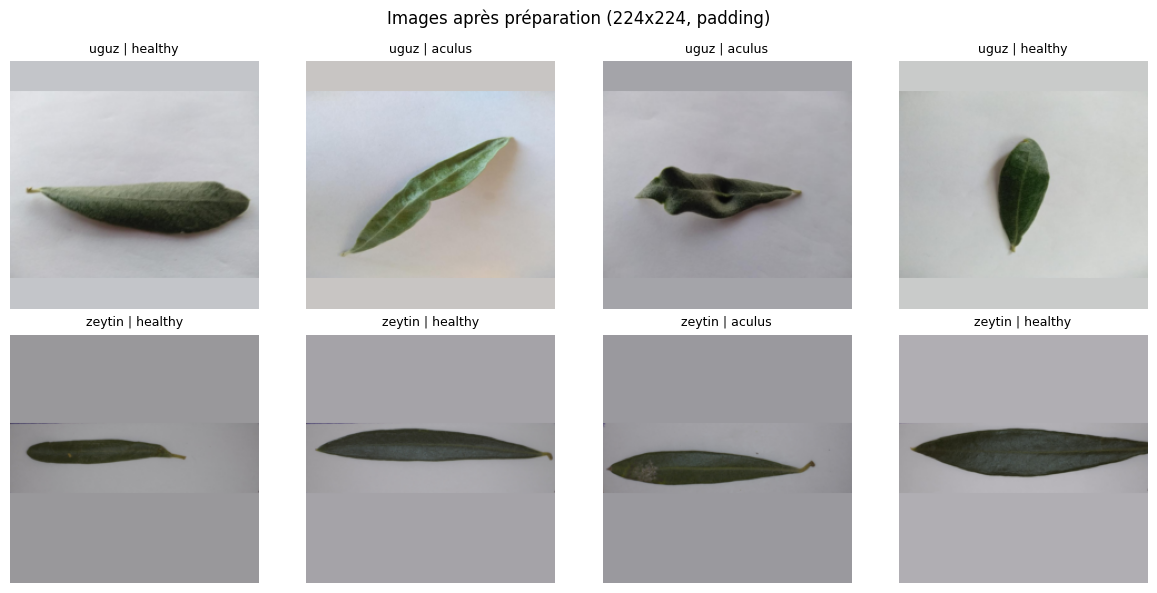

In [12]:
# Cellule 8 : préparer toutes les images en 224x224 (une seule fois)
import numpy as np
from PIL import Image, ImageOps

TAILLE = 224
CLASSES = ["healthy", "aculus", "peacock_spot"]   # ordre fixé pour tout le projet

def charger(chemin):
    with Image.open(chemin) as img:
        img = img.convert("RGB")
        a = np.asarray(img)
        # couleur du fond = médiane des 5 premières et 5 dernières lignes de pixels
        bord = np.concatenate([a[:5].reshape(-1, 3), a[-5:].reshape(-1, 3)])
        couleur = tuple(int(v) for v in np.median(bord, axis=0))
        # redimensionne sans déformer + complète en carré
        img = ImageOps.pad(img, (TAILLE, TAILLE), color=couleur, method=Image.BILINEAR)
    return np.asarray(img, dtype=np.uint8)
    
splits = pd.read_csv("/kaggle/working/splits.csv")

with ThreadPoolExecutor(max_workers=16) as ex:
    X = np.stack(list(ex.map(charger, splits["chemin"])))
y = splits["classe"].map({c: i for i, c in enumerate(CLASSES)}).values

print("Forme de X :", X.shape)          # (4120, 224, 224, 3)
print("Mémoire utilisée :", round(X.nbytes / 1e6), "Mo")

np.save("/kaggle/working/X.npy", X)
np.save("/kaggle/working/y.npy", y)

# Vérification visuelle : 4 images Uğuz + 4 images Zeytin après préparation
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ligne, source in enumerate(["uguz", "zeytin"]):
    idx = splits[splits["source"] == source].sample(4, random_state=0).index
    for col, i in enumerate(idx):
        axes[ligne, col].imshow(X[i])
        axes[ligne, col].set_title(f"{source} | {splits.loc[i, 'classe']}", fontsize=9)
        axes[ligne, col].axis("off")
plt.suptitle("Images après préparation (224x224, padding)")
plt.tight_layout()
plt.show()

---
# 6. Entraînement des modèles

## 6.1 Outils communs
Nous définissons une seule fois les outils utilisés par **tous les modèles**, afin que la comparaison soit équitable
(mêmes données, mêmes augmentations, même procédure d'entraînement).

**Vocabulaire :**
- **Transfer learning** : on part d'un modèle déjà entraîné sur ImageNet (1,2 million d'images) et on remplace
  sa dernière couche par une couche à 3 sorties (nos 3 classes).
- **Batch** : paquet de 32 images traitées en même temps.
- **Époque (epoch)** : un passage complet sur toutes les images d'entraînement.
- **Augmentation de données** : à chaque époque, les images d'entraînement sont légèrement modifiées
  (recadrage, retournement, couleurs) pour que le modèle apprenne la maladie et non une image précise.
- **Early stopping** : on arrête l'entraînement si le score de validation ne progresse plus pendant 4 époques,
  et on garde la meilleure version du modèle.

**Paramètres :**

| Paramètre | Valeur |
| :--- | :--- |
| Taille d'entrée | 224×224, normalisation ImageNet |
| Augmentations | recadrage aléatoire (80–100 %), retournements H/V, variation de luminosité/contraste/saturation |
| Optimiseur | AdamW, taux d'apprentissage 1e-4 |
| Fonction de perte | Entropie croisée |
| Batch | 32 |
| Époques max | 15 (early stopping, patience 4) |
| Métrique de sélection | **F1 macro** sur la validation |
| Précision mixte (AMP) | oui (entraînement plus rapide sur GPU) |

In [13]:
# Cellule 9 : outils communs pour entraîner et évaluer les modèles
import time
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models
from torchvision.transforms import v2 as T
from sklearn.metrics import f1_score, accuracy_score

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Appareil :", device, "|", torch.cuda.get_device_name(0) if device == "cuda" else "PAS DE GPU !")

# --- 1) Transformations des images ---
MOYENNE, ECART = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]   # normalisation ImageNet

transfo_train = T.Compose([
    T.ToImage(),
    T.RandomResizedCrop(224, scale=(0.8, 1.0), antialias=True),  # recadrage aléatoire
    T.RandomHorizontalFlip(),
    T.RandomVerticalFlip(),
    T.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    T.ToDtype(torch.float32, scale=True),
    T.Normalize(MOYENNE, ECART),
])
transfo_eval = T.Compose([
    T.ToImage(),
    T.ToDtype(torch.float32, scale=True),
    T.Normalize(MOYENNE, ECART),
])

# --- 2) Dataset : donne une image (transformée) + sa classe ---
class OliveDataset(Dataset):
    def __init__(self, indices, transfo):
        self.indices = np.asarray(indices)
        self.transfo = transfo
    def __len__(self):
        return len(self.indices)
    def __getitem__(self, k):
        i = self.indices[k]
        return self.transfo(X[i]), int(y[i])

idx = {s: splits.index[splits["split"] == s].values for s in ["train", "val", "test", "externe"]}
loaders = {
    "train":   DataLoader(OliveDataset(idx["train"], transfo_train), batch_size=32, shuffle=True, num_workers=2),
    "val":     DataLoader(OliveDataset(idx["val"], transfo_eval), batch_size=64, num_workers=2),
    "test":    DataLoader(OliveDataset(idx["test"], transfo_eval), batch_size=64, num_workers=2),
    "externe": DataLoader(OliveDataset(idx["externe"], transfo_eval), batch_size=64, num_workers=2),
}
print({s: len(v) for s, v in idx.items()})

# --- 3) Créer un modèle pré-entraîné avec 3 sorties ---
def creer_modele(nom):
    if nom == "resnet50":
        m = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
        m.fc = nn.Linear(m.fc.in_features, 3)
    elif nom == "efficientnet_b0":
        m = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, 3)
    return m.to(device)

# --- 4) Prédire sur un ensemble d'images ---
@torch.no_grad()
def predire(modele, loader):
    modele.eval()
    vrais, probas = [], []
    for images, etiquettes in loader:
        with torch.autocast(device_type="cuda", enabled=(device == "cuda")):
            sorties = modele(images.to(device))
        probas.append(torch.softmax(sorties.float(), dim=1).cpu())
        vrais.append(etiquettes)
    probas = torch.cat(probas).numpy()
    return torch.cat(vrais).numpy(), probas.argmax(1), probas

# --- 5) Entraîner avec early stopping ---
def entrainer(nom, epochs=15, lr=1e-4, patience=4):
    modele = creer_modele(nom)
    optimiseur = torch.optim.AdamW(modele.parameters(), lr=lr)
    critere = nn.CrossEntropyLoss()
    scaler = torch.amp.GradScaler("cuda", enabled=(device == "cuda"))

    meilleur_f1, attente, historique = -1, 0, []
    chemin_sauvegarde = f"/kaggle/working/model_{nom}.pt"

    for epoch in range(1, epochs + 1):
        debut = time.time()
        modele.train()
        somme_perte, bons, total = 0.0, 0, 0
        for images, etiquettes in loaders["train"]:
            images, etiquettes = images.to(device), etiquettes.to(device)
            optimiseur.zero_grad()
            with torch.autocast(device_type="cuda", enabled=(device == "cuda")):
                sorties = modele(images)
                perte = critere(sorties, etiquettes)
            scaler.scale(perte).backward()
            scaler.step(optimiseur)
            scaler.update()
            somme_perte += perte.item() * len(etiquettes)
            bons += (sorties.argmax(1) == etiquettes).sum().item()
            total += len(etiquettes)

        y_val, p_val, _ = predire(modele, loaders["val"])
        f1_val = f1_score(y_val, p_val, average="macro")
        historique.append({
            "epoch": epoch,
            "perte_train": somme_perte / total,
            "acc_train": bons / total,
            "acc_val": accuracy_score(y_val, p_val),
            "f1_val": f1_val,
        })
        print(f"Époque {epoch:2d} | perte {somme_perte/total:.3f} | acc train {bons/total:.3f} "
              f"| acc val {historique[-1]['acc_val']:.3f} | F1 val {f1_val:.3f} | {time.time()-debut:.0f}s")

        if f1_val > meilleur_f1:
            meilleur_f1, attente = f1_val, 0
            torch.save(modele.state_dict(), chemin_sauvegarde)
            print("   ↳ meilleur modèle sauvegardé")
        else:
            attente += 1
            if attente >= patience:
                print(f"Arrêt anticipé (pas d'amélioration depuis {patience} époques)")
                break

    modele.load_state_dict(torch.load(chemin_sauvegarde))
    historique = pd.DataFrame(historique)
    historique.to_csv(f"/kaggle/working/historique_{nom}.csv", index=False)
    print(f"\nMeilleur F1 validation ({nom}) : {meilleur_f1:.4f}")
    return modele, historique

# --- 6) Tracer les courbes d'apprentissage ---
def tracer(historique, titre):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(historique["epoch"], historique["perte_train"], marker="o")
    axes[0].set_title("Perte d'entraînement"); axes[0].set_xlabel("Époque")
    axes[1].plot(historique["epoch"], historique["acc_train"], marker="o", label="train")
    axes[1].plot(historique["epoch"], historique["acc_val"], marker="o", label="validation")
    axes[1].plot(historique["epoch"], historique["f1_val"], marker="o", label="F1 validation")
    axes[1].set_title("Exactitude et F1"); axes[1].set_xlabel("Époque"); axes[1].legend()
    fig.suptitle(titre); plt.tight_layout(); plt.show()

Appareil : cuda | Tesla T4
{'train': 2216, 'val': 475, 'test': 475, 'externe': 954}


## 6.2 Modèle baseline : ResNet50
**ResNet50** (He et al., 2016) est un réseau de neurones convolutif de 50 couches (~25 millions de paramètres),
très utilisé comme référence en vision par ordinateur. Ses « connexions résiduelles » permettent d'entraîner
des réseaux profonds sans que l'apprentissage ne se bloque.

Il nous sert de **baseline** : le modèle avancé devra faire au moins aussi bien.

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 188MB/s] 


Époque  1 | perte 0.473 | acc train 0.837 | acc val 0.920 | F1 val 0.915 | 17s
   ↳ meilleur modèle sauvegardé
Époque  2 | perte 0.139 | acc train 0.952 | acc val 0.947 | F1 val 0.946 | 10s
   ↳ meilleur modèle sauvegardé
Époque  3 | perte 0.116 | acc train 0.965 | acc val 0.964 | F1 val 0.962 | 10s
   ↳ meilleur modèle sauvegardé
Époque  4 | perte 0.100 | acc train 0.966 | acc val 0.962 | F1 val 0.961 | 11s
Époque  5 | perte 0.075 | acc train 0.977 | acc val 0.973 | F1 val 0.972 | 11s
   ↳ meilleur modèle sauvegardé
Époque  6 | perte 0.051 | acc train 0.984 | acc val 0.966 | F1 val 0.965 | 11s
Époque  7 | perte 0.061 | acc train 0.977 | acc val 0.973 | F1 val 0.971 | 11s
Époque  8 | perte 0.040 | acc train 0.990 | acc val 0.966 | F1 val 0.963 | 11s
Époque  9 | perte 0.040 | acc train 0.988 | acc val 0.977 | F1 val 0.975 | 11s
   ↳ meilleur modèle sauvegardé
Époque 10 | perte 0.052 | acc train 0.986 | acc val 0.979 | F1 val 0.978 | 11s
   ↳ meilleur modèle sauvegardé
Époque 11 | perte 

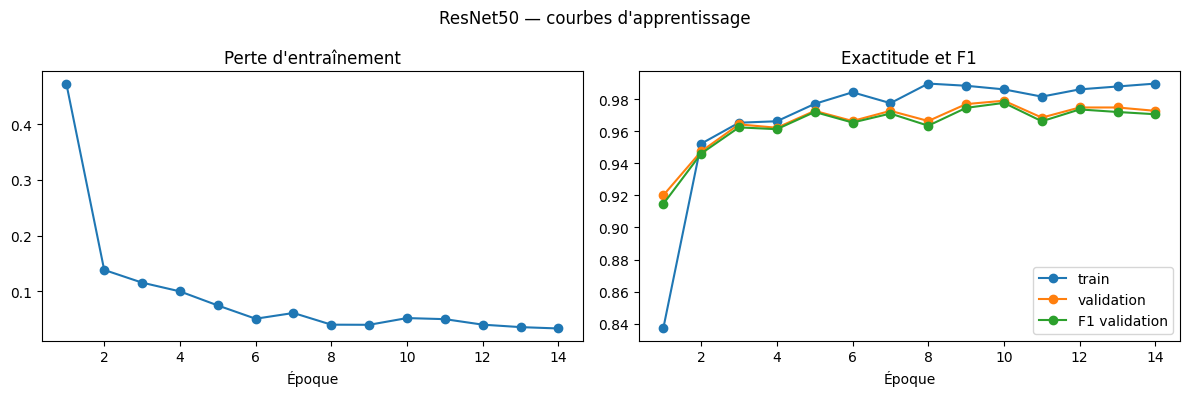

In [14]:
# Cellule 10 : entraîner la baseline ResNet50
modele_resnet, hist_resnet = entrainer("resnet50")
tracer(hist_resnet, "ResNet50 — courbes d'apprentissage")

**Résultats ResNet50 :**
- Meilleur **F1 macro validation : 0,978** (époque 10), ~11 s par époque sur GPU.
- L'entraînement s'est arrêté à l'époque 14 (early stopping) ; le modèle de l'époque 10 est conservé.
- La perte diminue rapidement puis se stabilise : le modèle converge.
- Léger écart entre l'exactitude d'entraînement (~99 %) et de validation (~97 %) : **faible sur-apprentissage**,
  contenu par l'augmentation de données et l'early stopping.
- ⚠️ Ce score est mesuré sur des images de **même distribution** que l'entraînement (Uğuz).
  La capacité de généralisation sera évaluée sur Zeytin (section 8).

## 6.3 Modèle avancé : EfficientNet-B0
**EfficientNet-B0** (Tan & Le, 2019) est un réseau conçu pour équilibrer automatiquement la **profondeur**,
la **largeur** et la **résolution** du réseau. Il atteint une précision comparable à ResNet50 avec environ
**5 fois moins de paramètres** (~4 millions contre ~24 millions), ce qui le rend plus léger et plus rapide
à déployer (API, mobile).

Pour une comparaison **équitable**, il est entraîné avec **exactement la même procédure** que la baseline :
mêmes données, mêmes augmentations, mêmes hyperparamètres.

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 138MB/s] 


Époque  1 | perte 0.651 | acc train 0.774 | acc val 0.914 | F1 val 0.914 | 14s
   ↳ meilleur modèle sauvegardé
Époque  2 | perte 0.225 | acc train 0.926 | acc val 0.928 | F1 val 0.928 | 8s
   ↳ meilleur modèle sauvegardé
Époque  3 | perte 0.152 | acc train 0.952 | acc val 0.960 | F1 val 0.960 | 8s
   ↳ meilleur modèle sauvegardé
Époque  4 | perte 0.116 | acc train 0.960 | acc val 0.966 | F1 val 0.966 | 8s
   ↳ meilleur modèle sauvegardé
Époque  5 | perte 0.104 | acc train 0.965 | acc val 0.956 | F1 val 0.954 | 8s
Époque  6 | perte 0.082 | acc train 0.968 | acc val 0.960 | F1 val 0.959 | 9s
Époque  7 | perte 0.083 | acc train 0.974 | acc val 0.954 | F1 val 0.952 | 8s
Époque  8 | perte 0.070 | acc train 0.977 | acc val 0.964 | F1 val 0.962 | 8s
Arrêt anticipé (pas d'amélioration depuis 4 époques)

Meilleur F1 validation (efficientnet_b0) : 0.9657


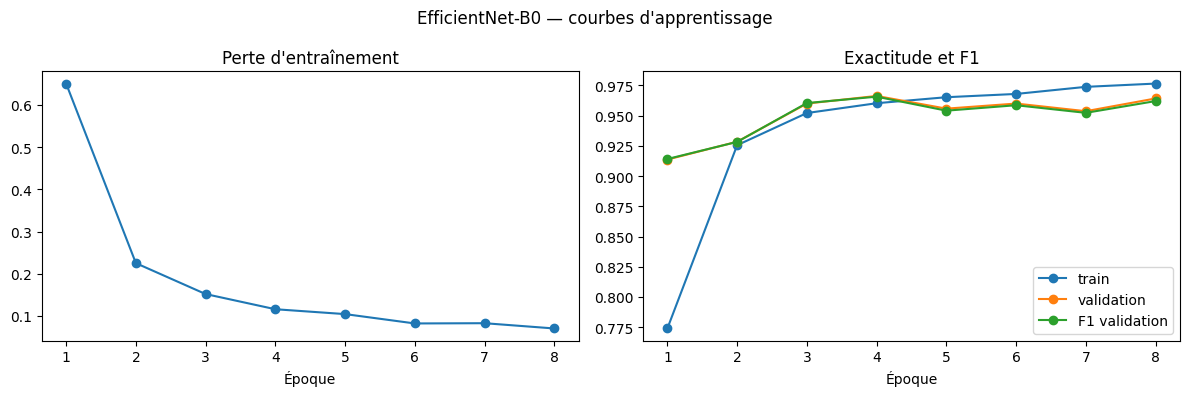

In [15]:
# Cellule 11 : entraîner le modèle avancé EfficientNet-B0
modele_effnet, hist_effnet = entrainer("efficientnet_b0")
tracer(hist_effnet, "EfficientNet-B0 — courbes d'apprentissage")

**Résultats EfficientNet-B0 (essai 1, lr = 1e-4) :**
- Meilleur **F1 macro validation : 0,966** (époque 4), ~8 s par époque (plus rapide que ResNet50).
- Arrêt anticipé à l'époque 8, alors que l'exactitude d'entraînement progressait encore :
  le modèle n'a probablement **pas fini de converger**.
- Hypothèse : le taux d'apprentissage de 1e-4, adapté à ResNet50, est **trop faible pour EfficientNet**,
  qui est habituellement entraîné avec un taux plus élevé.

## 6.4 Réglage d'EfficientNet-B0 (essai 2)
On relance EfficientNet-B0 avec :
- un **taux d'apprentissage de 3e-4** (au lieu de 1e-4),
- une **patience de 6 époques** (au lieu de 4) et **20 époques maximum** (au lieu de 15).

Le premier essai est conservé (fichiers renommés `..._lr1e-4`) pour pouvoir comparer les deux réglages.

Époque  1 | perte 0.389 | acc train 0.859 | acc val 0.937 | F1 val 0.936 | 8s
   ↳ meilleur modèle sauvegardé
Époque  2 | perte 0.162 | acc train 0.945 | acc val 0.943 | F1 val 0.942 | 8s
   ↳ meilleur modèle sauvegardé
Époque  3 | perte 0.128 | acc train 0.954 | acc val 0.954 | F1 val 0.950 | 8s
   ↳ meilleur modèle sauvegardé
Époque  4 | perte 0.101 | acc train 0.966 | acc val 0.975 | F1 val 0.973 | 8s
   ↳ meilleur modèle sauvegardé
Époque  5 | perte 0.076 | acc train 0.972 | acc val 0.966 | F1 val 0.964 | 8s
Époque  6 | perte 0.078 | acc train 0.977 | acc val 0.952 | F1 val 0.948 | 8s
Époque  7 | perte 0.068 | acc train 0.975 | acc val 0.945 | F1 val 0.943 | 8s
Époque  8 | perte 0.053 | acc train 0.983 | acc val 0.968 | F1 val 0.965 | 8s
Époque  9 | perte 0.066 | acc train 0.983 | acc val 0.966 | F1 val 0.962 | 8s
Époque 10 | perte 0.058 | acc train 0.981 | acc val 0.977 | F1 val 0.974 | 8s
   ↳ meilleur modèle sauvegardé
Époque 11 | perte 0.061 | acc train 0.978 | acc val 0.977 | 

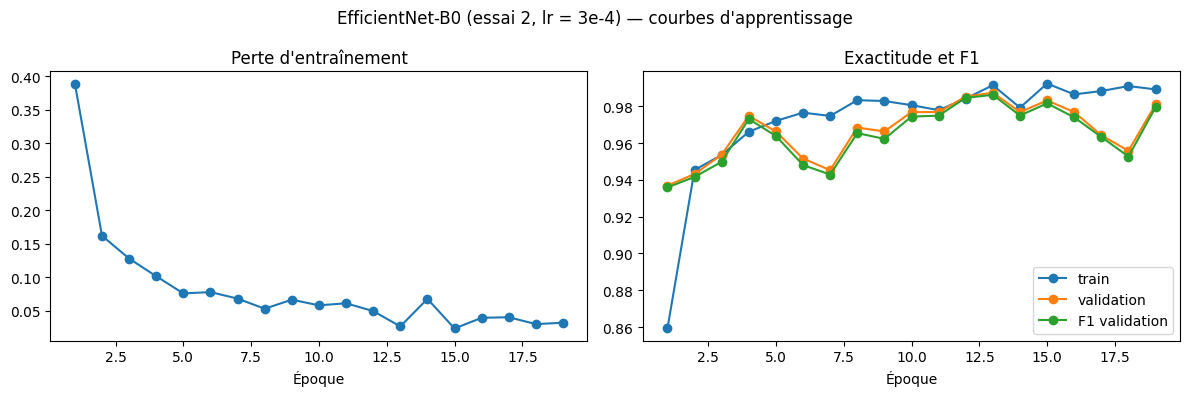

In [16]:
# Cellule 12 : 2e essai d'EfficientNet-B0 avec un taux d'apprentissage plus élevé
import os

# On garde le 1er essai en le renommant (sinon il serait écrasé)
os.rename("/kaggle/working/model_efficientnet_b0.pt", "/kaggle/working/model_efficientnet_b0_lr1e-4.pt")
os.rename("/kaggle/working/historique_efficientnet_b0.csv", "/kaggle/working/historique_efficientnet_b0_lr1e-4.csv")

modele_effnet, hist_effnet = entrainer("efficientnet_b0", epochs=20, lr=3e-4, patience=6)
tracer(hist_effnet, "EfficientNet-B0 (essai 2, lr = 3e-4) — courbes d'apprentissage")

**Résultats EfficientNet-B0 (essai 2, lr = 3e-4) :**
- Meilleur **F1 macro validation : 0,986** (époque 13), contre 0,966 pour l'essai 1 et 0,978 pour ResNet50.
- Le taux d'apprentissage plus élevé permet une meilleure convergence, au prix d'une courbe de validation
  plus irrégulière (creux aux époques 7 et 18) ; l'early stopping conserve la meilleure époque.

**Récapitulatif (validation) :**

| Modèle | lr | F1 macro val | Époque retenue |
| :--- | :---: | :---: | :---: |
| ResNet50 (baseline) | 1e-4 | 0,978 | 10 |
| EfficientNet-B0 essai 1 | 1e-4 | 0,966 | 4 |
| **EfficientNet-B0 essai 2** | **3e-4** | **0,986** | 13 |

*Limite : par manque de temps, ResNet50 n'a pas été testé avec d'autres taux d'apprentissage.*

---
# 7. Évaluation et comparaison des modèles

Les deux modèles retenus (ResNet50 et EfficientNet-B0 essai 2) sont évalués **une seule fois** sur le
**jeu de test Uğuz** (475 images jamais vues pendant l'entraînement ni pendant les réglages).

**Métriques :**
- **Exactitude** : proportion de bonnes prédictions.
- **Précision** (par classe) : quand le modèle prédit une classe, à quelle fréquence a-t-il raison ?
- **Rappel** (par classe) : parmi les images d'une classe, combien sont retrouvées ?
- **F1** : moyenne harmonique de la précision et du rappel ; **F1 macro** = moyenne des F1 des 3 classes.
- **Matrice de confusion** : quelles classes sont confondues entre elles.
- **Coût** : nombre de paramètres, taille du fichier, temps d'inférence par image (GPU et CPU).
  Le temps CPU est important car l'API sera déployée sans GPU.

ResNet50
              precision    recall  f1-score   support

     healthy      0.963     1.000     0.981       130
      aculus      0.977     0.954     0.965       131
peacock_spot      0.981     0.972     0.977       214

    accuracy                          0.975       475
   macro avg      0.974     0.975     0.974       475
weighted avg      0.975     0.975     0.975       475

EfficientNet-B0
              precision    recall  f1-score   support

     healthy      0.977     0.985     0.981       130
      aculus      0.977     0.992     0.985       131
peacock_spot      0.995     0.981     0.988       214

    accuracy                          0.985       475
   macro avg      0.983     0.986     0.985       475
weighted avg      0.985     0.985     0.985       475



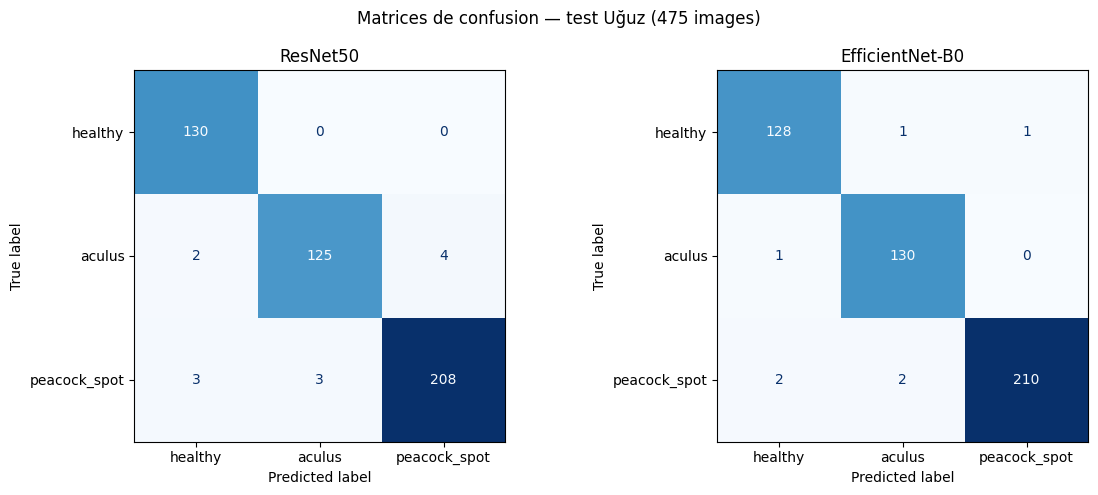

,modèle,exactitude,F1 macro,paramètres (M),taille fichier (Mo),temps GPU (ms/img),temps CPU (ms/img)
0,ResNet50,0.975,0.974,23.514,94.377,5.845,81.437
1,EfficientNet-B0,0.985,0.985,4.011,16.349,8.548,34.128


In [18]:
# Cellule 13 : évaluation complète des deux modèles sur le test Uğuz
import copy
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

def mesurer_temps(modele, appareil, repetitions):
    """Temps moyen (en ms) pour analyser UNE image."""
    m = copy.deepcopy(modele).to(appareil).eval()
    x = torch.randn(1, 3, 224, 224, device=appareil)
    with torch.no_grad():
        for _ in range(5):                       # échauffement
            m(x)
        if appareil == "cuda": torch.cuda.synchronize()
        debut = time.time()
        for _ in range(repetitions):
            m(x)
        if appareil == "cuda": torch.cuda.synchronize()
    return (time.time() - debut) / repetitions * 1000

modeles = {
    "ResNet50": (modele_resnet, "/kaggle/working/model_resnet50.pt"),
    "EfficientNet-B0": (modele_effnet, "/kaggle/working/model_efficientnet_b0.pt"),
}

lignes = []
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (nom, (modele, fichier)) in zip(axes, modeles.items()):
    y_true, y_pred, _ = predire(modele, loaders["test"])

    print("=" * 60)
    print(nom)
    print(classification_report(y_true, y_pred, target_names=CLASSES, digits=3))

    ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred), display_labels=CLASSES).plot(
        ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(nom)

    lignes.append({
        "modèle": nom,
        "exactitude": accuracy_score(y_true, y_pred),
        "F1 macro": f1_score(y_true, y_pred, average="macro"),
        "paramètres (M)": sum(p.numel() for p in modele.parameters()) / 1e6,
        "taille fichier (Mo)": os.path.getsize(fichier) / 1e6,
        "temps GPU (ms/img)": mesurer_temps(modele, "cuda", 50),
        "temps CPU (ms/img)": mesurer_temps(modele, "cpu", 10),
    })

plt.suptitle("Matrices de confusion — test Uğuz (475 images)")
plt.tight_layout()
plt.savefig("/kaggle/working/matrices_confusion_test.png", dpi=150)
plt.show()

comparaison = pd.DataFrame(lignes).round(3)
comparaison.to_csv("/kaggle/working/comparaison_modeles.csv", index=False)
display(comparaison)

**Résultats sur le test Uğuz (475 images) :**

| Modèle | Exactitude | F1 macro | Paramètres | Taille | CPU (ms/img) | GPU (ms/img) |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: |
| ResNet50 | 0,975 | 0,974 | 23,5 M | 94 Mo | 81 | 5,8 |
| **EfficientNet-B0** | **0,985** | **0,985** | **4,0 M** | **16 Mo** | **34** | 8,5 |

- **EfficientNet-B0 est meilleur** (7 erreurs contre 12) tout en étant **6 fois plus petit** et
  **2,4 fois plus rapide sur CPU**, l'environnement de déploiement de l'API.
- Sur GPU avec une image à la fois, ResNet50 est plus rapide (architecture plus simple à paralléliser),
  ce qui n'a pas d'impact pour notre usage.
- La classe la plus difficile est **aculus** : ResNet50 en confond 4 avec l'œil de paon (rappel 0,954) ;
  EfficientNet-B0 atteint un rappel de 0,992.
- Les scores de test sont proches de ceux de validation : **pas de sur-apprentissage sur la validation**.

**→ Modèle retenu pour le déploiement : EfficientNet-B0.**

---
# 8. Test de généralisation et détection de drift (Zeytin)

## 8.1 Protocole
Les modèles n'ont **jamais vu** d'images Zeytin. Comme les étiquettes fines de Zeytin sont peu fiables
(section 2.2), l'évaluation se fait en **binaire** :
- **sain** = prédiction `healthy`,
- **malade** = prédiction `aculus` ou `peacock_spot`.

Les mêmes métriques binaires sont calculées sur le test Uğuz pour comparer.

## 8.2 Test de Kolmogorov-Smirnov (KS)
Le test KS compare deux distributions et renvoie :
- une **statistique D** (entre 0 et 1 : 0 = distributions identiques, 1 = complètement différentes),
- une **p-value** : si p < 0,05, on conclut que les distributions sont **significativement différentes** (drift).

On l'applique à :
1. la **luminosité moyenne** des images (drift des données d'entrée),
2. la **confiance du modèle** (probabilité maximale), un signal surveillable en production **sans étiquettes**.

ResNet50 — matrice de confusion Zeytin (lignes = vrai, colonnes = prédit)
             prédit sain  prédit malade
vrai sain            506             66
vrai malade            8            374

Pour les feuilles Zeytin 'malades', le modèle prédit :
peacock_spot    372
healthy           8
aculus            2
Name: count, dtype: int64

EfficientNet-B0 — matrice de confusion Zeytin (lignes = vrai, colonnes = prédit)
             prédit sain  prédit malade
vrai sain            380            192
vrai malade            4            378

Pour les feuilles Zeytin 'malades', le modèle prédit :
peacock_spot    366
aculus           12
healthy           4
Name: count, dtype: int64



,modèle,acc binaire test Uğuz,acc binaire Zeytin,F1 binaire test Uğuz,F1 binaire Zeytin,confiance moy. test Uğuz,confiance moy. Zeytin
0,ResNet50,0.989,0.922,0.993,0.910,0.971,0.918
1,EfficientNet-B0,0.989,0.795,0.993,0.794,0.993,0.876


TEST DE KOLMOGOROV-SMIRNOV (test Uğuz vs Zeytin)
Luminosité des images      : D = 0.871 | p-value = 8.80e-253
Confiance ResNet50        : D = 0.436 | p-value = 1.16e-54
Confiance EfficientNet-B0 : D = 0.565 | p-value = 4.73e-94


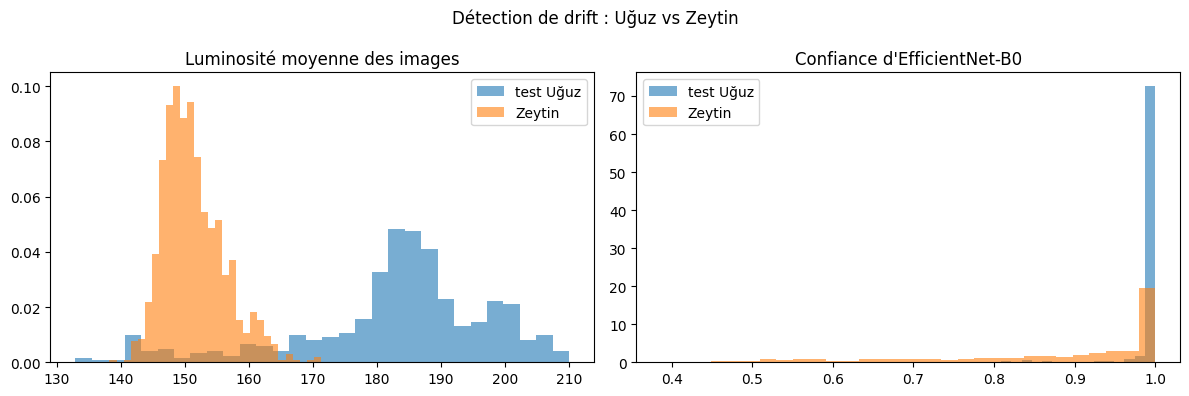

In [19]:
# Cellule 14 : test sur Zeytin (binaire sain / malade) + test KS
from scipy.stats import ks_2samp

def binaire(classes):
    return (np.asarray(classes) != 0).astype(int)     # 0 = sain, 1 = malade

resultats = []
confiances = {}
for nom, (modele, _) in modeles.items():
    yt_test, yp_test, pr_test = predire(modele, loaders["test"])
    yt_ext, yp_ext, pr_ext = predire(modele, loaders["externe"])
    confiances[nom] = (pr_test.max(1), pr_ext.max(1))

    resultats.append({
        "modèle": nom,
        "acc binaire test Uğuz": accuracy_score(binaire(yt_test), binaire(yp_test)),
        "acc binaire Zeytin": accuracy_score(binaire(yt_ext), binaire(yp_ext)),
        "F1 binaire test Uğuz": f1_score(binaire(yt_test), binaire(yp_test)),
        "F1 binaire Zeytin": f1_score(binaire(yt_ext), binaire(yp_ext)),
        "confiance moy. test Uğuz": pr_test.max(1).mean(),
        "confiance moy. Zeytin": pr_ext.max(1).mean(),
    })

    print("=" * 60)
    print(nom, "— matrice de confusion Zeytin (lignes = vrai, colonnes = prédit)")
    print(pd.DataFrame(confusion_matrix(binaire(yt_ext), binaire(yp_ext)),
                       index=["vrai sain", "vrai malade"], columns=["prédit sain", "prédit malade"]))
    print("\nPour les feuilles Zeytin 'malades', le modèle prédit :")
    print(pd.Series(yp_ext[yt_ext != 0]).map(dict(enumerate(CLASSES))).value_counts())
    print()

display(pd.DataFrame(resultats).round(3))

# --- Test KS ---
print("=" * 60)
print("TEST DE KOLMOGOROV-SMIRNOV (test Uğuz vs Zeytin)")
lum_test = X[idx["test"]].mean(axis=(1, 2, 3))
lum_ext = X[idx["externe"]].mean(axis=(1, 2, 3))
ks = ks_2samp(lum_test, lum_ext)
print(f"Luminosité des images      : D = {ks.statistic:.3f} | p-value = {ks.pvalue:.2e}")
for nom, (c_test, c_ext) in confiances.items():
    ks = ks_2samp(c_test, c_ext)
    print(f"Confiance {nom:16s}: D = {ks.statistic:.3f} | p-value = {ks.pvalue:.2e}")

# --- Graphiques ---
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(lum_test, bins=30, alpha=0.6, density=True, label="test Uğuz")
axes[0].hist(lum_ext, bins=30, alpha=0.6, density=True, label="Zeytin")
axes[0].set_title("Luminosité moyenne des images"); axes[0].legend()
c_test, c_ext = confiances["EfficientNet-B0"]
axes[1].hist(c_test, bins=30, alpha=0.6, density=True, label="test Uğuz")
axes[1].hist(c_ext, bins=30, alpha=0.6, density=True, label="Zeytin")
axes[1].set_title("Confiance d'EfficientNet-B0"); axes[1].legend()
plt.suptitle("Détection de drift : Uğuz vs Zeytin")
plt.tight_layout()
plt.savefig("/kaggle/working/drift_ks.png", dpi=150)
plt.show()

**Résultats du test de généralisation (binaire sain / malade) :**

| Modèle | Exactitude test Uğuz | Exactitude Zeytin | F1 Zeytin | Faux « malade » (sur 572 sains) | Malades manqués (sur 382) |
| :--- | :---: | :---: | :---: | :---: | :---: |
| ResNet50 | 0,989 | **0,922** | **0,910** | 66 | 8 |
| EfficientNet-B0 | 0,989 | 0,795 | 0,794 | 192 | 4 |

**Observations :**
1. **Confirmation de l'erreur d'étiquetage** : les feuilles Zeytin « malades » sont prédites `peacock_spot`
   à 97 % (ResNet50 : 372/382 ; EfficientNet-B0 : 366/382). Il s'agit donc d'**œil de paon** et non d'*Aculus*
   comme supposé par OLIVE-CAD.
2. **Inversion du classement** : EfficientNet-B0, meilleur sur le test Uğuz, est **nettement moins robuste**
   sur Zeytin (−19 points contre −7 pour ResNet50). Il produit surtout des **fausses alertes**
   (feuilles saines classées malades).
3. **Drift significatif (test KS)** :

   | Variable | Statistique D | p-value |
   | :--- | :---: | :---: |
   | Luminosité des images | 0,871 | 8,8e-253 |
   | Confiance ResNet50 | 0,436 | 1,2e-54 |
   | Confiance EfficientNet-B0 | 0,565 | 4,7e-94 |

   Les images Zeytin sont **nettement plus sombres** (luminosité moyenne ≈ 150 contre ≈ 185).
   La **baisse de confiance** du modèle est un indicateur de drift **mesurable sans étiquettes**,
   utilisable en production pour déclencher une alerte.

**Conclusion :** une meilleure performance sur des données de même distribution ne garantit pas une
meilleure généralisation. Le choix du modèle de déploiement doit tenir compte de la robustesse.

## 8.3 Atténuation du drift : augmentation de luminosité renforcée
Le test KS indique que la **luminosité** est la principale source de drift. Hypothèse : en exposant le modèle
à des variations de luminosité et de contraste plus fortes pendant l'entraînement, il deviendra moins sensible
à ce facteur.

EfficientNet-B0 est réentraîné avec les mêmes réglages que l'essai 2 (lr = 3e-4), mais avec :
`ColorJitter(brightness=0.5, contrast=0.5, saturation=0.3, hue=0.03)` au lieu de `(0.2, 0.2, 0.2)`.

⚠️ Zeytin reste un jeu **jamais utilisé pour l'entraînement ni pour la sélection du modèle** : seule la validation
Uğuz sert à choisir la meilleure époque.

Époque  1 | perte 0.450 | acc train 0.833 | acc val 0.886 | F1 val 0.880 | 11s
   ↳ meilleur modèle sauvegardé
Époque  2 | perte 0.205 | acc train 0.926 | acc val 0.935 | F1 val 0.932 | 11s
   ↳ meilleur modèle sauvegardé
Époque  3 | perte 0.163 | acc train 0.947 | acc val 0.966 | F1 val 0.965 | 11s
   ↳ meilleur modèle sauvegardé
Époque  4 | perte 0.122 | acc train 0.958 | acc val 0.971 | F1 val 0.969 | 12s
   ↳ meilleur modèle sauvegardé
Époque  5 | perte 0.105 | acc train 0.962 | acc val 0.926 | F1 val 0.921 | 12s
Époque  6 | perte 0.137 | acc train 0.950 | acc val 0.966 | F1 val 0.965 | 11s
Époque  7 | perte 0.088 | acc train 0.968 | acc val 0.966 | F1 val 0.965 | 11s
Époque  8 | perte 0.093 | acc train 0.967 | acc val 0.964 | F1 val 0.962 | 11s
Époque  9 | perte 0.066 | acc train 0.980 | acc val 0.968 | F1 val 0.967 | 11s
Époque 10 | perte 0.093 | acc train 0.969 | acc val 0.966 | F1 val 0.963 | 11s
Arrêt anticipé (pas d'amélioration depuis 6 époques)

Meilleur F1 validation (effi

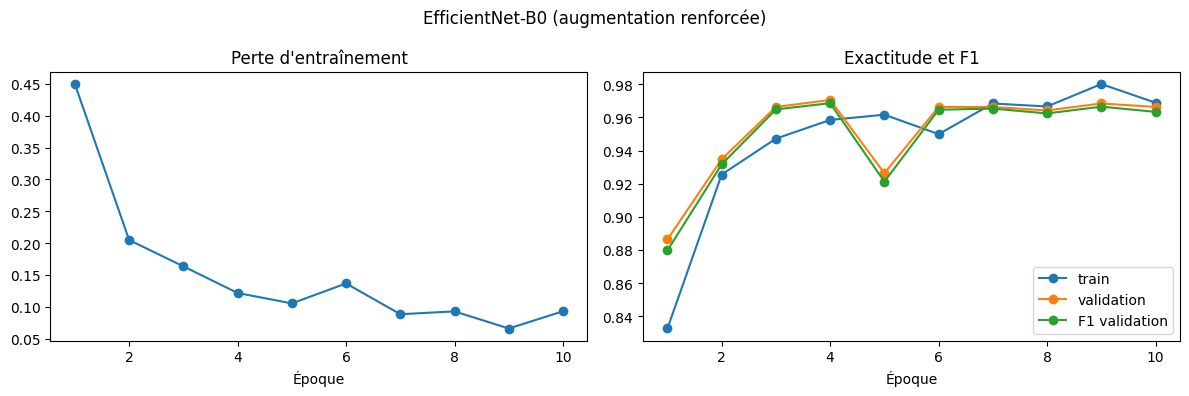

,modèle,F1 macro test Uğuz (3 classes),acc binaire Zeytin,F1 binaire Zeytin,faux malades (/572),malades manqués (/382),confiance moy. Zeytin
0,ResNet50,0.974,0.922,0.910,66,8,0.918
1,EfficientNet-B0,0.985,0.795,0.794,192,4,0.876
2,EfficientNet-B0 aug+,0.969,0.894,0.882,98,3,0.901


In [20]:
# Cellule 15 : EfficientNet-B0 avec une augmentation de luminosité renforcée

# 1) Nouvelle transformation d'entraînement (seul ColorJitter change)
transfo_train_fort = T.Compose([
    T.ToImage(),
    T.RandomResizedCrop(224, scale=(0.8, 1.0), antialias=True),
    T.RandomHorizontalFlip(),
    T.RandomVerticalFlip(),
    T.ColorJitter(brightness=0.5, contrast=0.5, saturation=0.3, hue=0.03),   # plus fort
    T.ToDtype(torch.float32, scale=True),
    T.Normalize(MOYENNE, ECART),
])
loader_train_normal = loaders["train"]
loaders["train"] = DataLoader(OliveDataset(idx["train"], transfo_train_fort),
                              batch_size=32, shuffle=True, num_workers=2)

# 2) creer_modele accepte maintenant des noms comme "efficientnet_b0_augfort"
def creer_modele(nom):
    if nom.startswith("resnet50"):
        m = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
        m.fc = nn.Linear(m.fc.in_features, 3)
    elif nom.startswith("efficientnet_b0"):
        m = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, 3)
    return m.to(device)

# 3) Entraînement
modele_effnet_aug, hist_effnet_aug = entrainer("efficientnet_b0_augfort", epochs=20, lr=3e-4, patience=6)
loaders["train"] = loader_train_normal      # on remet l'ancien loader
tracer(hist_effnet_aug, "EfficientNet-B0 (augmentation renforcée)")

# 4) Comparaison des 3 modèles : test Uğuz + Zeytin
modeles["EfficientNet-B0 aug+"] = (modele_effnet_aug, "/kaggle/working/model_efficientnet_b0_augfort.pt")
bilan = []
for nom, (modele, _) in modeles.items():
    yt_test, yp_test, _ = predire(modele, loaders["test"])
    yt_ext, yp_ext, pr_ext = predire(modele, loaders["externe"])
    cm = confusion_matrix(binaire(yt_ext), binaire(yp_ext))
    bilan.append({
        "modèle": nom,
        "F1 macro test Uğuz (3 classes)": f1_score(yt_test, yp_test, average="macro"),
        "acc binaire Zeytin": accuracy_score(binaire(yt_ext), binaire(yp_ext)),
        "F1 binaire Zeytin": f1_score(binaire(yt_ext), binaire(yp_ext)),
        "faux malades (/572)": cm[0, 1],
        "malades manqués (/382)": cm[1, 0],
        "confiance moy. Zeytin": pr_ext.max(1).mean(),
    })
bilan = pd.DataFrame(bilan).round(3)
bilan.to_csv("/kaggle/working/bilan_drift.csv", index=False)
display(bilan)

**Résultats de l'atténuation :**

| Modèle | F1 macro test Uğuz | Exactitude Zeytin | F1 Zeytin | Faux malades (/572) | Malades manqués (/382) | Confiance moy. Zeytin |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: |
| ResNet50 | 0,974 | **0,922** | **0,910** | **66** | 8 | 0,918 |
| EfficientNet-B0 | **0,985** | 0,795 | 0,794 | 192 | 4 | 0,876 |
| EfficientNet-B0 aug+ | 0,969 | 0,894 | 0,882 | 98 | **3** | 0,901 |

- L'augmentation renforcée **divise par 2 les fausses alertes** d'EfficientNet-B0 (192 → 98) et améliore
  l'exactitude sur Zeytin de **+10 points**, ce qui confirme le rôle de la luminosité dans le drift.
- Contrepartie : légère baisse sur le test Uğuz (0,985 → 0,969) → **compromis performance / robustesse**.
- **ResNet50 reste le modèle le plus robuste**, sans correction particulière.

**Décision : ResNet50 est retenu pour le déploiement** (meilleure robustesse, F1 test de 0,974,
temps CPU de 81 ms/image compatible avec une API). EfficientNet-B0 aug+ est conservé comme alternative légère.

⚠️ **Limite** : Zeytin ayant servi à comparer les modèles, il ne constitue plus un test totalement indépendant.
Une validation finale sur de **nouvelles photos de terrain** (feuilles d'oliviers tunisiens) est nécessaire.

---
# 9. Explicabilité : Grad-CAM

**Grad-CAM** (Selvaraju et al., 2017) calcule, pour une prédiction donnée, l'importance de chaque zone de l'image :
1. on récupère les **cartes d'activation** de la dernière couche convolutive (`layer4` pour ResNet50),
2. on calcule le **gradient** du score de la classe prédite par rapport à ces cartes,
3. on pondère chaque carte par l'importance moyenne de son gradient, puis on additionne
   → carte de chaleur (rouge = zone déterminante pour la décision).

**Objectifs :**
- vérifier que le modèle s'appuie sur la **feuille et ses symptômes** et non sur le fond,
- comprendre les **fausses alertes** observées sur Zeytin.

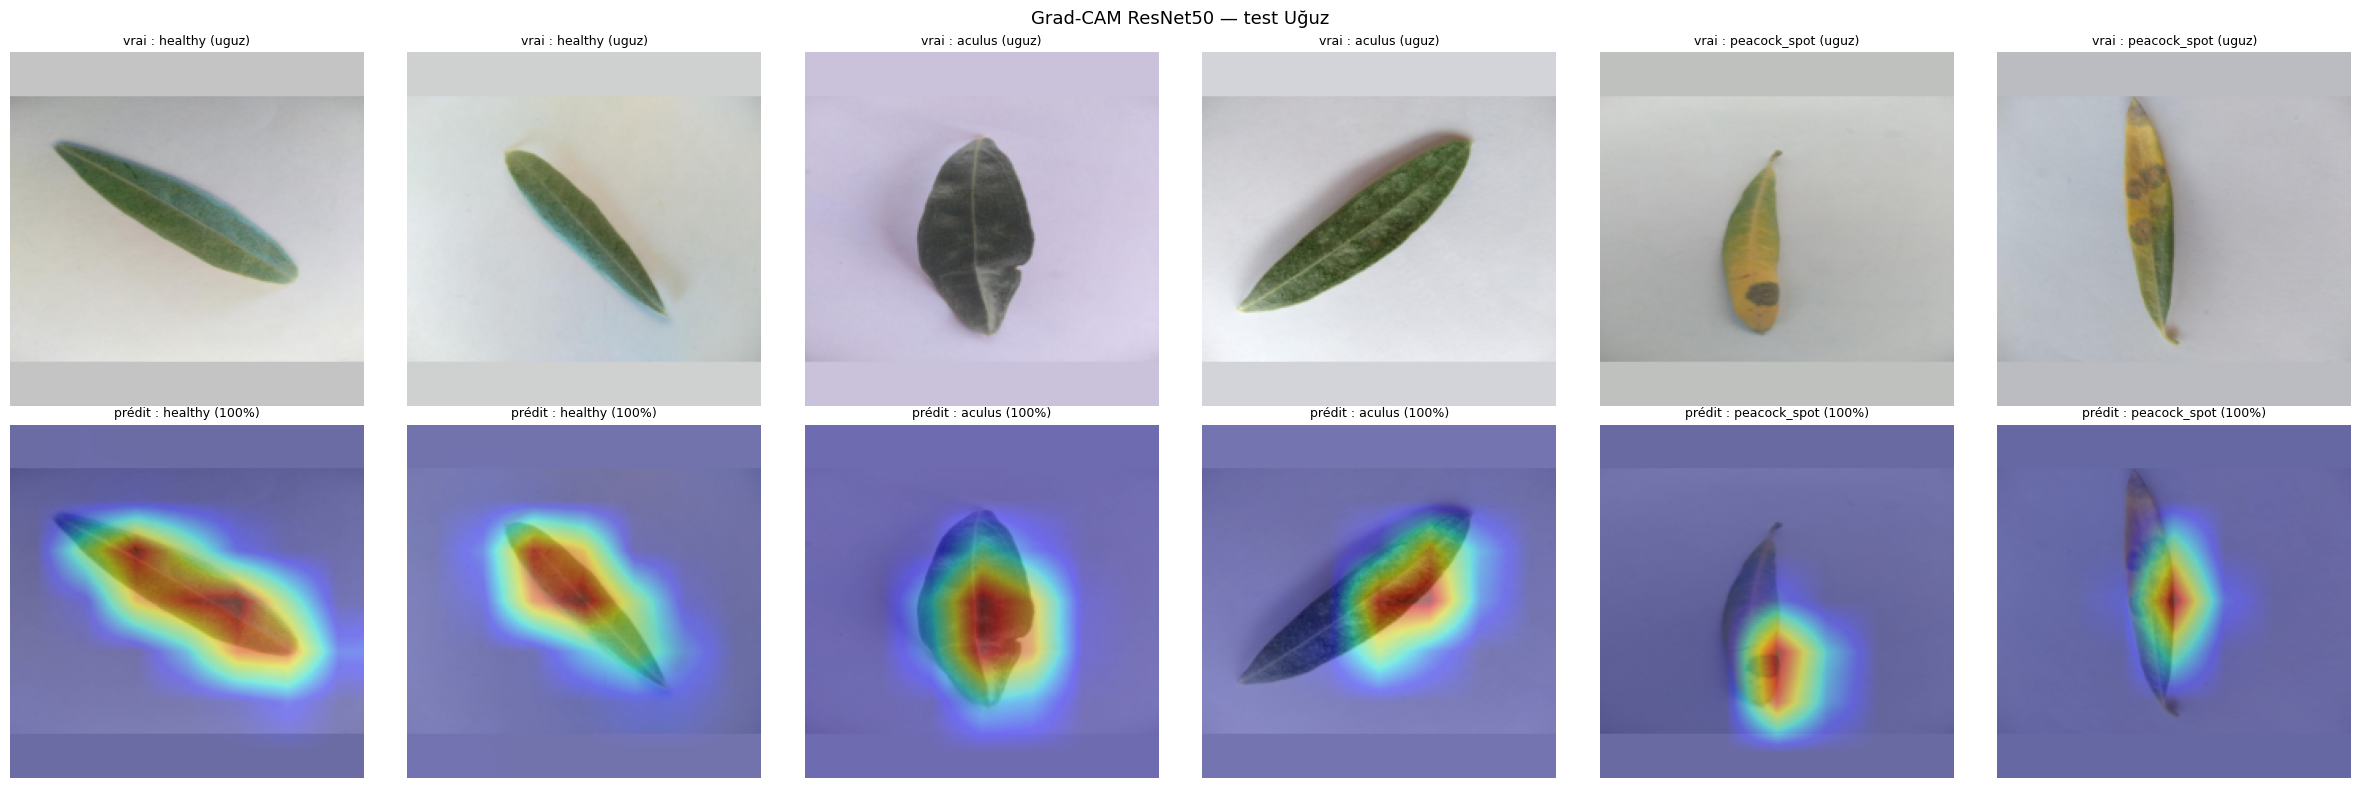

Nombre de fausses alertes ResNet50 sur Zeytin : 66


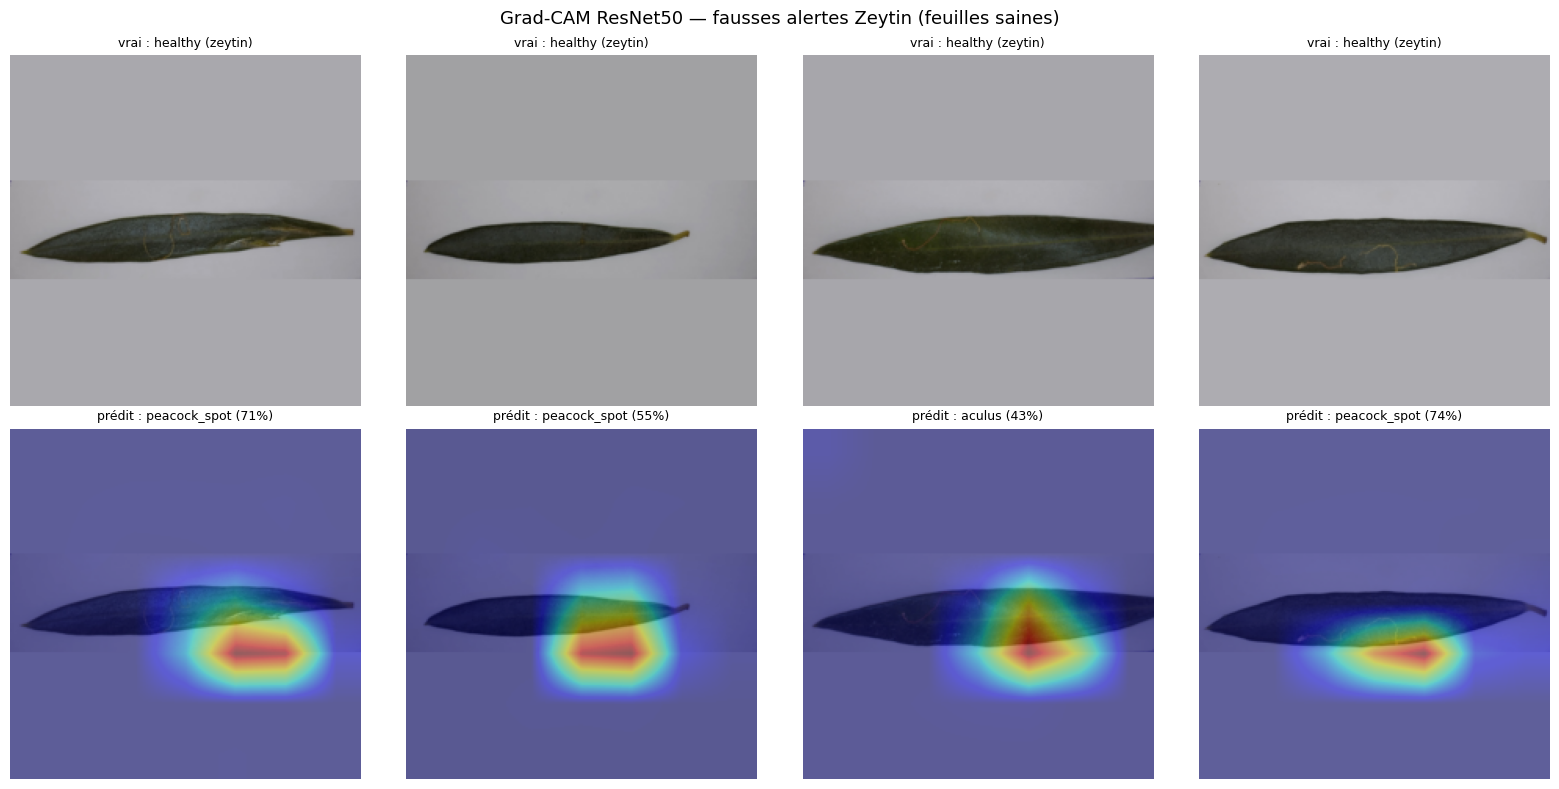

In [22]:
# Cellule 16 : Grad-CAM sur le modèle retenu (ResNet50)
import torch.nn.functional as F
modele_resnet.layer4[-1]._forward_hooks.clear()   # débranche les anciens "micros" restés accrochés

class GradCAM:
    def __init__(self, modele, couche):
        self.modele = modele.eval()
        self.activations, self.gradients = None, None
        couche.register_forward_hook(self._garder)

    def _garder(self, module, entree, sortie):
        self.activations = sortie.detach()
        if sortie.requires_grad:      # seulement quand on calcule Grad-CAM (pas pendant predire)
            sortie.register_hook(lambda g: setattr(self, "gradients", g.detach()))

    def __call__(self, image_tensor):
        x = image_tensor.unsqueeze(0).to(device)
        sortie = self.modele(x)                         # pas d'autocast : calcul en float32
        classe = sortie.argmax(1).item()
        self.modele.zero_grad()
        sortie[0, classe].backward()                    # gradient du score de la classe prédite
        poids = self.gradients.mean(dim=(2, 3), keepdim=True)
        cam = F.relu((poids * self.activations).sum(dim=1)).squeeze()
        cam = cam / (cam.max() + 1e-8)
        cam = F.interpolate(cam[None, None], size=(224, 224), mode="bilinear").squeeze().cpu().numpy()
        proba = torch.softmax(sortie, dim=1)[0, classe].item()
        return cam, classe, proba

gradcam = GradCAM(modele_resnet, modele_resnet.layer4[-1])

def afficher_gradcam(indices, titre):
    fig, axes = plt.subplots(2, len(indices), figsize=(4 * len(indices), 8))
    for col, i in enumerate(indices):
        cam, classe, proba = gradcam(transfo_eval(X[i]))
        axes[0, col].imshow(X[i])
        axes[0, col].set_title(f"vrai : {splits.loc[i, 'classe']} ({splits.loc[i, 'source']})", fontsize=9)
        axes[1, col].imshow(X[i])
        axes[1, col].imshow(cam, cmap="jet", alpha=0.45)
        axes[1, col].set_title(f"prédit : {CLASSES[classe]} ({proba:.0%})", fontsize=9)
        for ax in axes[:, col]:
            ax.axis("off")
    fig.suptitle(titre, fontsize=13)
    plt.tight_layout()
    return fig

# 1) Uğuz test : 2 images par classe
ex_uguz = []
for c in CLASSES:
    ex_uguz += list(splits[(splits["split"] == "test") & (splits["classe"] == c)].sample(2, random_state=3).index)
fig1 = afficher_gradcam(ex_uguz, "Grad-CAM ResNet50 — test Uğuz")
fig1.savefig("/kaggle/working/gradcam_uguz.png", dpi=120); plt.show()

# 2) Zeytin : feuilles SAINES prédites MALADES (fausses alertes)
_, yp_ext_resnet, _ = predire(modele_resnet, loaders["externe"])
fausses_alertes = idx["externe"][(y[idx["externe"]] == 0) & (yp_ext_resnet != 0)]
print("Nombre de fausses alertes ResNet50 sur Zeytin :", len(fausses_alertes))
fig2 = afficher_gradcam(fausses_alertes[:4], "Grad-CAM ResNet50 — fausses alertes Zeytin (feuilles saines)")
fig2.savefig("/kaggle/working/gradcam_zeytin_erreurs.png", dpi=120); plt.show()

**Observations — test Uğuz :**
- Sur toutes les images, la zone d'attention (rouge) est **située sur la feuille** et non sur le fond :
  le modèle **ne s'appuie pas sur la couleur du fond**, risque identifié lors de l'EDA.
- Pour `peacock_spot`, l'attention se concentre sur les **taches brunes et les zones jaunies**,
  c'est-à-dire les **symptômes** de la maladie.
- Pour `healthy` et `aculus`, l'attention couvre une large partie de la feuille : ces classes se distinguent
  par l'aspect global (forme, déformation, texture) plutôt que par une lésion localisée.


**Observations — fausses alertes Zeytin (feuilles saines prédites malades) :**
- La **confiance du modèle est faible** sur ces erreurs (43 % à 74 %), contre ~100 % sur les images Uğuz.
- L'attention se porte sur le **bord inférieur sombre de la feuille**, et non sur une lésion (il n'y en a pas) :
  les feuilles scannées étant **nettement plus sombres**, le modèle confond ces zones foncées avec des
  symptômes d'œil de paon. Cela confirme le rôle de la **luminosité** identifié par le test KS.

**Conséquence pour le déploiement :** les erreurs étant associées à une faible confiance, un **seuil de confiance**
permet de renvoyer « incertain » plutôt qu'un mauvais diagnostic.

---
# 10. Seuil de confiance et sauvegarde du modèle final

## 10.1 Choix du seuil de confiance
Si la probabilité maximale du modèle est **inférieure au seuil**, l'API répond **« incertain »** au lieu d'une classe.
On cherche un seuil qui :
- rejette **peu d'images** sur le test Uğuz (où le modèle est fiable),
- rejette une **grande partie des erreurs** sur Zeytin.

## 10.2 Sauvegarde
Le modèle retenu (**ResNet50**) est sauvegardé avec toutes les informations nécessaires à l'API :
architecture, ordre des classes, taille d'entrée, normalisation, seuil et métriques.
Il est aussi exporté au format **ONNX**, standard indépendant de PyTorch et plus rapide sur CPU.

In [23]:
# Cellule 17 : choix du seuil de confiance + sauvegarde du modèle final
yt_t, yp_t, pr_t = predire(modele_resnet, loaders["test"])
yt_e, yp_e, pr_e = predire(modele_resnet, loaders["externe"])
conf_t, conf_e = pr_t.max(1), pr_e.max(1)

# --- 1) Effet de différents seuils ---
lignes = []
for seuil in [0.0, 0.6, 0.7, 0.8, 0.9]:
    garde_t, garde_e = conf_t >= seuil, conf_e >= seuil
    erreurs_e = binaire(yt_e) != binaire(yp_e)
    lignes.append({
        "seuil": seuil,
        "% test Uğuz rejeté": 100 * (1 - garde_t.mean()),
        "exactitude test Uğuz (images gardées)": accuracy_score(yt_t[garde_t], yp_t[garde_t]),
        "% Zeytin rejeté": 100 * (1 - garde_e.mean()),
        "exactitude Zeytin binaire (gardées)": accuracy_score(binaire(yt_e[garde_e]), binaire(yp_e[garde_e])),
        "% des erreurs Zeytin interceptées": 100 * (erreurs_e & ~garde_e).sum() / erreurs_e.sum(),
    })
tableau_seuils = pd.DataFrame(lignes).round(3)
tableau_seuils.to_csv("/kaggle/working/seuils_confiance.csv", index=False)
display(tableau_seuils)

SEUIL_CONFIANCE = 0.8     # à ajuster après lecture du tableau

# --- 2) Sauvegarde du modèle final (PyTorch) ---
os.makedirs("/kaggle/working/models", exist_ok=True)
torch.save({
    "state_dict": modele_resnet.state_dict(),
    "architecture": "resnet50",
    "classes": CLASSES,
    "taille_entree": 224,
    "moyenne": MOYENNE,
    "ecart": ECART,
    "seuil_confiance": SEUIL_CONFIANCE,
    "metriques": {
        "f1_macro_test_uguz": float(f1_score(yt_t, yp_t, average="macro")),
        "acc_binaire_zeytin": float(accuracy_score(binaire(yt_e), binaire(yp_e))),
    },
}, "/kaggle/working/models/model_V1.pt")
print("✅ Sauvegardé : models/model_V1.pt")

# --- 3) Export ONNX ---
try:
    m_cpu = copy.deepcopy(modele_resnet).cpu().eval()
    torch.onnx.export(
        m_cpu, torch.randn(1, 3, 224, 224), "/kaggle/working/models/model_V1.onnx",
        input_names=["image"], output_names=["logits"],
        dynamic_axes={"image": {0: "batch"}, "logits": {0: "batch"}},
        dynamo=False,
    )
    print("✅ Exporté : models/model_V1.onnx")
except Exception as e:
    print("⚠️ Export ONNX impossible ici :", e)

,seuil,% test Uğuz rejeté,exactitude test Uğuz (images gardées),% Zeytin rejeté,exactitude Zeytin binaire (gardées),% des erreurs Zeytin interceptées
0,0.0,0.000,0.975,0.000,0.922,0.000
1,0.6,2.105,0.987,5.975,0.949,37.838
2,0.7,2.947,0.987,9.958,0.958,51.351
3,0.8,4.842,0.989,15.514,0.971,68.919
4,0.9,8.421,0.991,24.423,0.981,81.081


✅ Sauvegardé : models/model_V1.pt


/tmp/ipykernel_50/3833895365.py:45: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(


✅ Exporté : models/model_V1.onnx


**Choix du seuil :**

| Seuil | % Uğuz rejeté | Exactitude Uğuz (gardées) | % Zeytin rejeté | Exactitude Zeytin (gardées) | Erreurs Zeytin interceptées |
| :---: | :---: | :---: | :---: | :---: | :---: |
| 0 (aucun) | 0 % | 0,975 | 0 % | 0,922 | 0 % |
| 0,6 | 2,1 % | 0,987 | 6,0 % | 0,949 | 37,8 % |
| 0,7 | 2,9 % | 0,987 | 10,0 % | 0,958 | 51,4 % |
| **0,8** | **4,8 %** | **0,989** | **15,5 %** | **0,971** | **68,9 %** |
| 0,9 | 8,4 % | 0,991 | 24,4 % | 0,981 | 81,1 % |

**Seuil retenu : 0,8.** Il intercepte **69 % des erreurs** sur Zeytin tout en ne rejetant que **4,8 %**
des images Uğuz. Au-delà (0,9), le taux de rejet devient trop élevé pour un usage réel.

**Fichiers produits :** `models/model_V1.pt` (poids + métadonnées) et `models/model_V1.onnx` (déploiement).

---
# 11. Suivi des expériences avec MLflow

Toutes les expériences sont enregistrées dans **MLflow** (expérience `olive-disease`), une *run* par essai :

| Run | Modèle | lr | Augmentation couleur |
| :--- | :--- | :---: | :--- |
| `resnet50_baseline` | ResNet50 | 1e-4 | standard (0,2) |
| `efficientnet_b0_lr1e-4` | EfficientNet-B0 | 1e-4 | standard (0,2) |
| `efficientnet_b0_lr3e-4` | EfficientNet-B0 | 3e-4 | standard (0,2) |
| `efficientnet_b0_augfort` | EfficientNet-B0 | 3e-4 | renforcée (0,5) |

Pour chaque run : **paramètres**, **courbes par époque** (perte, exactitude, F1 validation),
**métriques finales** (test Uğuz, Zeytin, coût). Le modèle déployé est marqué du tag `deploye = oui`
et ses fichiers (modèle ONNX, figures) sont joints comme artefacts.

**Stockage :** les métriques et paramètres sont enregistrés dans une base **SQLite** (`mlflow.db`), et les fichiers
joints dans `mlartifacts/` (le stockage par dossier `mlruns/` est désormais refusé par défaut par MLflow).
Pour les consulter en local : `mlflow ui --backend-store-uri sqlite:///mlflow.db`


In [27]:
# Cellule 18 : journaliser toutes les expériences dans MLflow
try:
    import mlflow
except ImportError:
    !pip install -q mlflow
    import mlflow

W = "/kaggle/working"
mlflow.set_tracking_uri(f"sqlite:///{W}/mlflow_olive.db")     # nouveau fichier, jamais ouvert

# Récupérer l'expérience si elle existe, sinon la créer
exp = mlflow.get_experiment_by_name("olive-disease")
if exp is None:
    mlflow.create_experiment("olive-disease", artifact_location=f"{W}/mlartifacts_olive")
else:
    # Sécurité anti-doublons : on supprime les anciens runs si on relance la cellule
    for run_id in mlflow.search_runs(experiment_ids=[exp.experiment_id])["run_id"]:
        mlflow.delete_run(run_id)
mlflow.set_experiment("olive-disease")

runs = [
    {"nom": "resnet50_baseline",       "modele": "resnet50",        "lr": 1e-4, "patience": 4, "epochs_max": 15,
     "color_jitter": "0.2/0.2/0.2",      "historique": "historique_resnet50.csv",                "bilan": "ResNet50"},
    {"nom": "efficientnet_b0_lr1e-4",  "modele": "efficientnet_b0", "lr": 1e-4, "patience": 4, "epochs_max": 15,
     "color_jitter": "0.2/0.2/0.2",      "historique": "historique_efficientnet_b0_lr1e-4.csv",  "bilan": None},
    {"nom": "efficientnet_b0_lr3e-4",  "modele": "efficientnet_b0", "lr": 3e-4, "patience": 6, "epochs_max": 20,
     "color_jitter": "0.2/0.2/0.2",      "historique": "historique_efficientnet_b0.csv",         "bilan": "EfficientNet-B0"},
    {"nom": "efficientnet_b0_augfort", "modele": "efficientnet_b0", "lr": 3e-4, "patience": 6, "epochs_max": 20,
     "color_jitter": "0.5/0.5/0.3/0.03", "historique": "historique_efficientnet_b0_augfort.csv", "bilan": "EfficientNet-B0 aug+"},
]
bilan_i = bilan.set_index("modèle")
comp_i = comparaison.set_index("modèle")

for r in runs:
    with mlflow.start_run(run_name=r["nom"]):
        # 1) Paramètres
        mlflow.log_params({
            "modele": r["modele"], "lr": r["lr"], "patience": r["patience"], "epochs_max": r["epochs_max"],
            "color_jitter": r["color_jitter"], "batch_size": 32, "optimiseur": "AdamW",
            "taille_entree": 224, "decoupage": "70/15/15 stratifie apres dedoublonnage", "seed": 42,
        })

        # 2) Courbes par époque
        hist = pd.read_csv(f"{W}/{r['historique']}")
        for _, h in hist.iterrows():
            mlflow.log_metrics({
                "perte_train": float(h["perte_train"]), "acc_train": float(h["acc_train"]),
                "acc_val": float(h["acc_val"]), "f1_val": float(h["f1_val"]),
            }, step=int(h["epoch"]))
        mlflow.log_metric("meilleur_f1_val", float(hist["f1_val"].max()))

        # 3) Métriques finales (test Uğuz + Zeytin)
        if r["bilan"] is not None:
            b = bilan_i.loc[r["bilan"]]
            mlflow.log_metrics({
                "f1_macro_test_uguz": float(b["F1 macro test Uğuz (3 classes)"]),
                "acc_binaire_zeytin": float(b["acc binaire Zeytin"]),
                "f1_binaire_zeytin": float(b["F1 binaire Zeytin"]),
                "faux_malades_zeytin": float(b["faux malades (/572)"]),
                "confiance_moy_zeytin": float(b["confiance moy. Zeytin"]),
            })

        # 4) Coût du modèle (seulement pour les modèles mesurés à la Cellule 13)
        if r["bilan"] is not None and r["bilan"] in comp_i.index:
            c = comp_i.loc[r["bilan"]]
            mlflow.log_metrics({
                "parametres_M": float(c["paramètres (M)"]),
                "taille_Mo": float(c["taille fichier (Mo)"]),
                "temps_cpu_ms": float(c["temps CPU (ms/img)"]),
            })

        # 5) Modèle déployé : tag + fichiers joints
        if r["nom"] == "resnet50_baseline":
            mlflow.set_tag("deploye", "oui")
            mlflow.log_param("seuil_confiance", SEUIL_CONFIANCE)
            for f in ["models/model_V1.onnx", "matrices_confusion_test.png", "drift_ks.png",
                      "gradcam_uguz.png", "gradcam_zeytin_erreurs.png", "seuils_confiance.csv"]:
                if os.path.exists(f"{W}/{f}"):
                    mlflow.log_artifact(f"{W}/{f}")

# Vérification : tableau récapitulatif des runs
res = mlflow.search_runs(experiment_names=["olive-disease"])
colonnes = ["tags.mlflow.runName", "params.lr", "params.color_jitter", "metrics.meilleur_f1_val",
            "metrics.f1_macro_test_uguz", "metrics.acc_binaire_zeytin", "tags.deploye"]
display(res[[c for c in colonnes if c in res.columns]])
print("✅ Runs enregistrés :", len(res))

2026/11/17 13:09:24 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/17 13:09:24 INFO mlflow.store.db.utils: Updating database tables


,tags.mlflow.runName,params.lr,params.color_jitter,metrics.meilleur_f1_val,metrics.f1_macro_test_uguz,metrics.acc_binaire_zeytin,tags.deploye
0,efficientnet_b0_augfort,0.0003,0.5/0.5/0.3/0.03,0.968612,0.969,0.894,None
1,efficientnet_b0_lr3e-4,0.0003,0.2/0.2/0.2,0.986211,0.985,0.795,None
2,efficientnet_b0_lr1e-4,0.0001,0.2/0.2/0.2,0.965693,NaN,NaN,None
3,resnet50_baseline,0.0001,0.2/0.2/0.2,0.977594,0.974,0.922,oui


✅ Runs enregistrés : 4


**Résultat :** 4 runs enregistrés dans l'expérience MLflow `olive-disease`.

| Run | lr | Augmentation | Meilleur F1 val | F1 macro test Uğuz |
| :--- | :---: | :---: | :---: | :---: |
| resnet50_baseline (**déployé**) | 1e-4 | 0,2 | 0,978 | 0,974 |
| efficientnet_b0_lr1e-4 | 1e-4 | 0,2 | 0,966 | — (non évalué) |
| efficientnet_b0_lr3e-4 | 3e-4 | 0,2 | 0,986 | 0,985 |
| efficientnet_b0_augfort | 3e-4 | 0,5 | 0,969 | 0,969 |

---
# 12. Export des livrables

Les fichiers produits sont rangés selon l'arborescence du projet, puis compressés dans une archive (~281 Mo) :

```
livrables/
├── models/              model_V1.pt, model_V1.onnx (ResNet50 déployé), model_V2_effnet_augfort.pt
├── Resultats/           matrices de confusion, Grad-CAM, drift, tableaux CSV, historiques d'entraînement
├── data/preprocessing/  splits.csv (découpage de référence)
├── mlflow.db            suivi MLflow (métriques, paramètres)
└── mlartifacts/         fichiers joints aux runs MLflow
```

*Note : `Resultats/doublons.csv` provient de la première méthode de détection (64 bits), écartée car elle produisait
des faux positifs (section 3) ; il est conservé à titre de trace.*


In [28]:
# Cellule 19 : ranger les livrables et créer une archive .zip
import shutil, glob

L = f"{W}/livrables"
shutil.rmtree(L, ignore_errors=True)            # repartir d'un dossier propre si on relance
for d in ["models", "Resultats", "data/preprocessing"]:
    os.makedirs(f"{L}/{d}", exist_ok=True)

# Modèles
shutil.copy(f"{W}/models/model_V1.pt", f"{L}/models/")
shutil.copy(f"{W}/models/model_V1.onnx", f"{L}/models/")
shutil.copy(f"{W}/model_efficientnet_b0_augfort.pt", f"{L}/models/model_V2_effnet_augfort.pt")

# Résultats (figures + tableaux)
for f in glob.glob(f"{W}/*.png") + glob.glob(f"{W}/*.csv"):
    if not f.endswith(("splits.csv", "images.csv")):
        shutil.copy(f, f"{L}/Resultats/")

# Découpage de référence
shutil.copy(f"{W}/splits.csv", f"{L}/data/preprocessing/")

# Suivi MLflow
shutil.copy(f"{W}/mlflow_olive.db", f"{L}/mlflow.db")
shutil.copytree(f"{W}/mlartifacts_olive", f"{L}/mlartifacts", dirs_exist_ok=True)

# Archive
shutil.make_archive(f"{W}/projet_olivier_livrables", "zip", L)
print("✅ Archive prête :", round(os.path.getsize(f"{W}/projet_olivier_livrables.zip") / 1e6, 1), "Mo\n")
for root, dirs, files in os.walk(L):
    if "mlartifacts" not in root:
        print(root.replace(L, "livrables"), "→", files)

✅ Archive prête : 280.8 Mo

livrables → ['mlflow.db']
livrables/models → ['model_V2_effnet_augfort.pt', 'model_V1.onnx', 'model_V1.pt']
livrables/Resultats → ['historique_efficientnet_b0_augfort.csv', 'historique_efficientnet_b0.csv', 'historique_resnet50.csv', 'matrices_confusion_test.png', 'historique_efficientnet_b0_lr1e-4.csv', 'gradcam_zeytin_erreurs.png', 'gradcam_uguz.png', 'seuils_confiance.csv', 'bilan_drift.csv', 'comparaison_modeles.csv', 'drift_ks.png', 'doublons.csv']
livrables/data → []
livrables/data/preprocessing → ['splits.csv']


---
# 13. Conclusion

## Résultats principaux

| Étape | Résultat clé |
| :--- | :--- |
| Données | 4 354 images (Uğuz 3 400 + Zeytin 954) → **4 120 après dédoublonnage** |
| Qualité des données | **107 groupes de doublons fuyaient** entre train et test d'origine d'Uğuz ; 8 groupes à étiquettes contradictoires ; étiquette « Aculus » de Zeytin **erronée** (il s'agit d'œil de paon) |
| Baseline ResNet50 | F1 macro test **0,974** ; exactitude binaire Zeytin **0,922** |
| EfficientNet-B0 (lr 3e-4) | F1 macro test **0,985**, 6× plus petit, 2,4× plus rapide sur CPU ; mais **0,795** sur Zeytin |
| EfficientNet-B0 aug+ | Zeytin **0,894** (fausses alertes divisées par 2), test 0,969 |
| Drift (test KS) | Luminosité D = 0,871 ; confiance D = 0,436 (ResNet50) → drift fort et **détectable sans étiquettes** |
| Grad-CAM | Le modèle regarde la **feuille et les lésions**, pas le fond ; les erreurs Zeytin viennent des **zones sombres** |
| Déploiement | **ResNet50** + **seuil de confiance 0,8** : 4,8 % de rejet sur Uğuz, **69 % des erreurs Zeytin interceptées** |

## Enseignements
1. **Un meilleur score de test ne garantit pas une meilleure robustesse** : le classement des modèles s'inverse
   hors de la distribution d'entraînement.
2. **La qualité des données publiques doit être vérifiée** : doublons, fuites et erreurs d'étiquetage
   gonflent les scores publiés.
3. **La confiance du modèle est un signal de surveillance utile en production**, mesurable sans étiquettes.

## Limites
- Zeytin a servi à **comparer les modèles** : ce n'est plus un test totalement indépendant.
- Les deux sources sont des photos **en conditions contrôlées** (fond uni, scanner), loin des photos de verger.
- Seul le taux d'apprentissage d'EfficientNet a été réglé ; ResNet50 n'a pas été optimisé.

## Perspectives
- Constituer un **jeu de test terrain** : photos de feuilles d'oliviers tunisiens prises au smartphone.
- Ajouter une **détection de la feuille** (YOLOv8n ou masque HSV) avant la classification.
- Déployer le modèle ONNX dans une **API FastAPI** (`/health`, `/predict` renvoyant classe, confiance, heatmap
  ou « incertain »), avec une **surveillance du drift** (KS / Evidently) sur la confiance et la luminosité.
